In [2]:
# ==========================================================================
# IMPORT ALL LIBRARIES
# ==========================================================================

import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import warnings
import glob
from pathlib import Path
from datetime import datetime
warnings.filterwarnings('ignore')

# Medical imaging
import nibabel as nib
import cv2

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F

# Visualization
import plotly.graph_objects as go
import plotly.io as pio
from skimage import measure

# Configure Plotly for VS Code
pio.renderers.default = 'vscode'
from scipy import ndimage
from scipy.ndimage import zoom
from scipy.spatial.distance import directed_hausdorff

# Progress bars
from tqdm.notebook import tqdm

# Set random seeds for reproducibility
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed(42)

print("=" * 70)
print("ALL LIBRARIES IMPORTED SUCCESSFULLY!")
print("=" * 70)
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

ALL LIBRARIES IMPORTED SUCCESSFULLY!
PyTorch version: 2.12.0.dev20260409+cu132
CUDA available: True
CUDA device: NVIDIA GeForce RTX 5090
CUDA memory: 34.19 GB


In [3]:
# ==========================================================================
# CUDA AND CPU OPTIMIZATIONS (from major.ipynb)
# ==========================================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Selected device: {device}")

# CUDA optimizations for RTX 5090 + Ryzen 9 9950X on Windows
torch.backends.cudnn.benchmark = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cuda.matmul.allow_tf32 = True
if hasattr(torch, 'set_float32_matmul_precision'):
    torch.set_float32_matmul_precision('high')

os.environ['OMP_NUM_THREADS'] = str(min(16, os.cpu_count() or 8))
os.environ['MKL_NUM_THREADS'] = os.environ['OMP_NUM_THREADS']

if torch.multiprocessing.get_start_method(allow_none=True) != 'spawn':
    torch.multiprocessing.set_start_method('spawn', force=True)

print(f"OMP_NUM_THREADS: {os.environ['OMP_NUM_THREADS']}")
print(f"cuDNN benchmark: {torch.backends.cudnn.benchmark}")
print(f"TF32 enabled: {torch.backends.cuda.matmul.allow_tf32}")

Selected device: cuda
OMP_NUM_THREADS: 16
cuDNN benchmark: True
TF32 enabled: True


In [4]:
# ==========================================================================
# DATASET PATHS - LOCAL DIRECTORIES (E:\aryan)
# ==========================================================================
# 2 datasets:
# 1. imagesTr / labelsTr  ->  Medical Segmentation Decathlon (NIfTI, nested folder)
# 2. kaggle               ->  Preprocessed slices (.npy) from Kaggle

BASE_DIR = r"E:\aryan"

# --- Dataset 1: Medical Segmentation Decathlon (imagesTr / labelsTr) ---
IMAGES_TR_DIR = os.path.join(BASE_DIR, "imagesTr")
LABELS_TR_DIR = os.path.join(BASE_DIR, "labelsTr")

# --- Dataset 2: Kaggle preprocessed (.npy slices) ---
KAGGLE_TRAIN_DIR = os.path.join(BASE_DIR, "kaggle", "working", "Preprocessed", "train")
KAGGLE_VAL_DIR = os.path.join(BASE_DIR, "kaggle", "working", "Preprocessed", "val")

# --- Outputs ---
VIZ_DIR = os.path.join(BASE_DIR, "notebook_outputs", "visualizations")
OUTPUT_DIR = os.path.join(BASE_DIR, "notebook_outputs", "outputs")
PRED_DIR = os.path.join(BASE_DIR, "notebook_outputs", "predictions")
os.makedirs(VIZ_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)

# --- Helper: resolve nested NIfTI paths (imagesTr/lung_001.nii/lung_001.nii) ---
def resolve_nii_path(parent_dir, folder_name):
    """Resolve the actual .nii file inside a nested folder."""
    folder_path = os.path.join(parent_dir, folder_name)
    if os.path.isdir(folder_path):
        for f in os.listdir(folder_path):
            if f.endswith('.nii') or f.endswith('.nii.gz'):
                return os.path.join(folder_path, f)
    return folder_path  # fallback if it's a plain file


# --- Scan Dataset 1 ---
imagesTr_folders = sorted([d for d in os.listdir(IMAGES_TR_DIR) if os.path.isdir(os.path.join(IMAGES_TR_DIR, d))])
labelsTr_folders = sorted([d for d in os.listdir(LABELS_TR_DIR) if os.path.isdir(os.path.join(LABELS_TR_DIR, d))])
common_decathlon = sorted(set(imagesTr_folders) & set(labelsTr_folders))

print(f"Dataset 1 (imagesTr/labelsTr): {len(common_decathlon)} matched pairs")

# --- Scan Dataset 2 ---
kaggle_train_subjects = sorted(os.listdir(KAGGLE_TRAIN_DIR)) if os.path.exists(KAGGLE_TRAIN_DIR) else []
kaggle_val_subjects = sorted(os.listdir(KAGGLE_VAL_DIR)) if os.path.exists(KAGGLE_VAL_DIR) else []
print(f"Dataset 2 (Kaggle):  train={len(kaggle_train_subjects)}, val={len(kaggle_val_subjects)}")

Dataset 1 (imagesTr/labelsTr): 63 matched pairs
Dataset 2 (Kaggle):  train=57, val=6


In [5]:

from celluloid import Camera

In [9]:
# Verify imagesTr (local dataset only)
sample_nii = resolve_nii_path(IMAGES_TR_DIR, common_decathlon[0]) if common_decathlon else "N/A"
print(f"imagesTr sample: {sample_nii}")
if os.path.exists(str(sample_nii)):
    img = nib.load(sample_nii)
    print(f"  Shape: {img.shape}")

imagesTr sample: E:\aryan\imagesTr\lung_001.nii\lung_001.nii
  Shape: (512, 512, 304)


Using slice path: E:\aryan\Aryan\working\Preprocessed1\train\0\reconstructed_data\3.npy


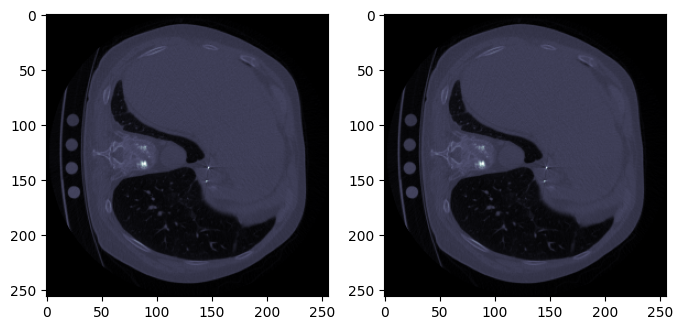

In [12]:
# Choose a file and load slice + mask
from pathlib import Path
file = "3.npy"
# Corrected path to match actual dataset structure
base_path = Path(r"E:\aryan\Aryan\working\Preprocessed1\train\0")
slice_path = base_path / "reconstructed_data" / file
mask_path = base_path / "masks" / file
print(f"Using slice path: {slice_path}")
if not slice_path.exists():
    print(f"Slice file not found: {slice_path}")
else:
    slice = np.load(slice_path)
    mask = np.load(mask_path)
    from IPython.display import HTML
    fig, axis = plt.subplots(1, 2, figsize=(8, 8))
    axis[0].imshow(slice, cmap="bone")
    mask_ = np.ma.masked_where(mask==0, mask)
    axis[1].imshow(slice, cmap="bone")
    axis[1].imshow(mask_, cmap="autumn")

In [13]:
import torch
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint
from pytorch_lightning.loggers import TensorBoardLogger
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from scipy.ndimage import rotate, shift, zoom as scipy_zoom
import random

W0418 15:14:05.823000 33224 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


In [14]:
import torch
from torch.utils.data import Dataset, DataLoader
import numpy as np
import os
from scipy.ndimage import rotate, shift, zoom as scipy_zoom
import random

def augment_slice_and_mask(slice_img, mask_img):
    """Apply random augmentations to both slice and mask identically using scipy."""
    angle = random.uniform(-45, 45)
    slice_img = rotate(slice_img, angle, reshape=False, order=1, mode='constant', cval=0)
    mask_img = rotate(mask_img, angle, reshape=False, order=0, mode='constant', cval=0)

    tx, ty = random.uniform(-0.15, 0.15) * slice_img.shape[0], random.uniform(-0.15, 0.15) * slice_img.shape[1]
    slice_img = shift(slice_img, [tx, ty], order=1, mode='constant', cval=0)
    mask_img = shift(mask_img, [tx, ty], order=0, mode='constant', cval=0)

    scale = random.uniform(0.85, 1.15)
    h, w = slice_img.shape
    zoomed_slice = scipy_zoom(slice_img, scale, order=1)
    zoomed_mask = scipy_zoom(mask_img, scale, order=0)
    zh, zw = zoomed_slice.shape
    if scale > 1:
        sh, sw = (zh - h) // 2, (zw - w) // 2
        slice_img = zoomed_slice[sh:sh+h, sw:sw+w]
        mask_img = zoomed_mask[sh:sh+h, sw:sw+w]
    else:
        result_s = np.zeros((h, w), dtype=slice_img.dtype)
        result_m = np.zeros((h, w), dtype=mask_img.dtype)
        sh, sw = (h - zh) // 2, (w - zw) // 2
        result_s[sh:sh+zh, sw:sw+zw] = zoomed_slice
        result_m[sh:sh+zh, sw:sw+zw] = zoomed_mask
        slice_img, mask_img = result_s, result_m

    return slice_img, mask_img


class LungDataset(Dataset):
    def __init__(self, root, augment=False):
        self.all_files = self.extract_files(root)
        self.augment = augment

    @staticmethod
    def extract_files(root):
        files = []
        for subject in os.listdir(root):
            slice_path = os.path.join(root, subject, "reconstructed_data")
            for s in os.listdir(slice_path):
                files.append(os.path.join(slice_path, s))
        return files

    @staticmethod
    def change_img_to_label_path(path):
        parts = list(Path(path).parts)
        parts[parts.index("reconstructed_data")] = "masks"
        return Path(*parts)

    def __len__(self):
        return len(self.all_files)

    def __getitem__(self, idx):
        file_path = self.all_files[idx]
        mask_path = self.change_img_to_label_path(file_path)
        slice_img = np.load(file_path).astype(np.float32)
        mask = np.load(mask_path).astype(np.float32)

        if self.augment:
            slice_img, mask = augment_slice_and_mask(slice_img, mask)

        return np.expand_dims(slice_img, 0), np.expand_dims(mask, 0)

In [15]:
class DoubleConv(torch.nn.Module):
    """
    Helper Class which implements the intermediate Convolutions
    """
    def __init__(self, in_channels, out_channels):
        
        super().__init__()
        self.step = torch.nn.Sequential(torch.nn.Conv2d(in_channels, out_channels, 3, padding=1),
                                        torch.nn.ReLU(),
                                        torch.nn.Conv2d(out_channels, out_channels, 3, padding=1),
                                        torch.nn.ReLU())
        
    def forward(self, X):
        return self.step(X)


class UNet(torch.nn.Module):
    """
    This class implements a UNet for the Segmentation
    We use 3 down- and 3 UpConvolutions and two Convolutions in each step
    """

    def __init__(self):
        """Sets up the U-Net Structure
        """
        super().__init__()
        
        
        ############# DOWN #####################
        self.layer1 = DoubleConv(1, 64)
        self.layer2 = DoubleConv(64, 128)
        self.layer3 = DoubleConv(128, 256)
        self.layer4 = DoubleConv(256, 512)

        #########################################

        ############## UP #######################
        self.layer5 = DoubleConv(512 + 256, 256)
        self.layer6 = DoubleConv(256+128, 128)
        self.layer7 = DoubleConv(128+64, 64)
        self.layer8 = torch.nn.Conv2d(64, 1, 1)
        #########################################

        self.maxpool = torch.nn.MaxPool2d(2)

    def forward(self, x):
        
        ####### DownConv 1#########
        x1 = self.layer1(x)
        x1m = self.maxpool(x1)
        ###########################
        
        ####### DownConv 2#########        
        x2 = self.layer2(x1m)
        x2m = self.maxpool(x2)
        ###########################

        ####### DownConv 3#########        
        x3 = self.layer3(x2m)
        x3m = self.maxpool(x3)
        ###########################
        
        ##### Intermediate Layer ## 
        x4 = self.layer4(x3m)
        ###########################

        ####### UpCONV 1#########        
        x5 = torch.nn.Upsample(scale_factor=2, mode="bilinear")(x4)  # Upsample with a factor of 2
        #x5 = torch.nn.ConvTranspose2d(512, 512, 2, 2)(x4)
        x5 = torch.cat([x5, x3], dim=1)  # Skip-Connection
        x5 = self.layer5(x5)
        ###########################

        ####### UpCONV 2#########        
        x6 = torch.nn.Upsample(scale_factor=2, mode="bilinear")(x5)        
        #x6 = torch.nn.ConvTranspose2d(256, 256, 2, 2)(x5)
        x6 = torch.cat([x6, x2], dim=1)  # Skip-Connection    
        x6 = self.layer6(x6)
        ###########################
        
        ####### UpCONV 3#########        
        x7 = torch.nn.Upsample(scale_factor=2, mode="bilinear")(x6)
        #x7 = torch.nn.ConvTranspose2d(128, 128, 2, 2)(x6)
        x7 = torch.cat([x7, x1], dim=1)       
        x7 = self.layer7(x7)
        ###########################
        
        ####### Predicted segmentation#########        
        ret = self.layer8(x7)
        return ret

In [16]:
# Augmentation is built into LungDataset using scipy
# (replaces imgaug which is incompatible with NumPy 2.x)
print("Augmentation: rotation(-45,45), translate(15%), scale(0.85-1.15) via scipy")

Augmentation: rotation(-45,45), translate(15%), scale(0.85-1.15) via scipy


In [18]:
# Set correct local dataset paths for Preprocessed1
train_path = r"E:\aryan\Aryan\working\Preprocessed1\train"
val_path = r"E:\aryan\Aryan\working\Preprocessed1\val"

train_dataset = LungDataset(train_path, augment=True)
val_dataset = LungDataset(val_path, augment=False)

print(f"There are {len(train_dataset)} train images and {len(val_dataset)} val images")

There are 14179 train images and 1588 val images


### Oversampling

Balance the training set so that approximately half of each batch contains tumor slices. This prevents the model from being biased toward predicting "no tumor" (the majority class).

In [19]:
# Create a list containing only the class labels (tumor vs no-tumor)
target_list = []
for _, label in tqdm(train_dataset):
    # Check if mask contains a tumorous pixel:
    if np.any(label):
        target_list.append(1)
    else:
        target_list.append(0)

uniques = np.unique(target_list, return_counts=True)
print(f"Class distribution: no-tumor={uniques[1][0]}, tumor={uniques[1][1]}")
fraction = uniques[1][0] / uniques[1][1]
print(f"Oversampling fraction: {fraction:.2f}")

  0%|          | 0/14179 [00:00<?, ?it/s]

Class distribution: no-tumor=12685, tumor=1494
Oversampling fraction: 8.49


In [20]:
# Create sample weights: tumor slices get higher weight so they appear ~50% of the time
weight_list = [1 if target == 0 else fraction for target in target_list]
sampler = torch.utils.data.sampler.WeightedRandomSampler(weight_list, len(weight_list))

In [21]:
# DataLoaders with weighted sampler for balanced training
batch_size = 8
num_workers = 0

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size,
                                           num_workers=num_workers, sampler=sampler,
                                           persistent_workers=False, pin_memory=True)
val_loader = torch.utils.data.DataLoader(val_dataset, batch_size=batch_size,
                                         num_workers=num_workers, shuffle=False,
                                         persistent_workers=False, pin_memory=True)

print(f"Train: {len(train_loader)} batches/epoch, Val: {len(val_loader)} batches/epoch")

Train: 1773 batches/epoch, Val: 199 batches/epoch


In [22]:
class DiceScore(torch.nn.Module):
    """
    class to compute the Dice Loss
    """
    def __init__(self):
        super().__init__()

    def forward(self, pred, mask):
                
        #flatten label and prediction tensors
        pred = torch.flatten(pred)
        mask = torch.flatten(mask)
        
        counter = (pred * mask).sum()  # Counter       
        denum = pred.sum() + mask.sum()  # denominator
        dice = (2*counter)/denum
        
        return dice

In [30]:
from sklearn.metrics import confusion_matrix

def plot_conf_matrix(y_true, y_pred, class_names=["Background", "Tumor"], title="Confusion Matrix"):
    import matplotlib.pyplot as plt
    import numpy as np
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 6))
    plt.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(class_names))
    plt.xticks(tick_marks, class_names, rotation=45)
    plt.yticks(tick_marks, class_names)
    thresh = cm.max() / 2.
    for i, j in np.ndindex(cm.shape):
        plt.text(j, i, f"{cm[i, j]}", horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    plt.ylabel("True Label")
    plt.xlabel("Predicted Label")
    plt.tight_layout()
    plt.show()


In [31]:
class TumorSegmentation(pl.LightningModule):
    def __init__(self):
        super().__init__()
        self.model = UNet()
        self.optimizer = torch.optim.Adam(self.model.parameters(), lr=1e-4)
        self.loss_fn = torch.nn.BCEWithLogitsLoss()
        self.train_losses = []
        self.val_losses = []
        self.val_dices = []
    
    def forward(self, data):
        data = data.float()
        pred = self.model(data)
        return pred
    
    def training_step(self, batch, batch_idx):
        ct, mask = batch
        mask = mask.float()
        pred = self(ct)
        loss = self.loss_fn(pred, mask)
        self.train_losses.append(loss.item())
        self.log("Train Loss", loss)
        if batch_idx % 50 == 0:
            self.log_images(ct.cpu(), pred.cpu(), mask.cpu(), "Train")
        return loss
    
    def validation_step(self, batch, batch_idx):
        ct, mask = batch
        mask = mask.float()
        pred = self(ct)
        loss = self.loss_fn(pred, mask)
        pred_bin = (torch.sigmoid(pred) > 0.5).float()
        dice = DiceScore()(pred_bin, mask)
        self.val_losses.append(loss.item())
        self.val_dices.append(dice.item())
        self.log("Val Loss", loss)
        self.log("Val Dice", dice)
        if batch_idx % 50 == 0:
            self.log_images(ct.cpu(), pred.cpu(), mask.cpu(), "Val")
        return {"val_loss": loss, "val_dice": dice}
    
    def log_images(self, ct, pred, mask, name):
        results = []
        pred = pred > 0.5
        fig, axis = plt.subplots(1, 2)
        axis[0].imshow(ct[0][0], cmap="bone")
        mask_ = np.ma.masked_where(mask[0][0]==0, mask[0][0])
        axis[0].imshow(mask_, alpha=0.6)
        axis[0].set_title("Ground Truth")
        axis[1].imshow(ct[0][0], cmap="bone")
        mask_ = np.ma.masked_where(pred[0][0]==0, pred[0][0])
        axis[1].imshow(mask_, alpha=0.6, cmap="autumn")
        axis[1].set_title("Pred")
        self.logger.experiment.add_figure(f"{name} Prediction vs Label", fig, self.global_step)
    
    def configure_optimizers(self):
        return [self.optimizer]

In [32]:
# Initialize model
MODEL_SAVE_DIR = os.path.join(BASE_DIR, "notebook_outputs", "models")
os.makedirs(MODEL_SAVE_DIR, exist_ok=True)

model = TumorSegmentation()

In [33]:
# Create the checkpoint callback
checkpoint_callback = ModelCheckpoint(
    dirpath=MODEL_SAVE_DIR,
    monitor='Val Dice',
    save_top_k=5,
    mode='min')  # BCEWithLogitsLoss: lower = better

In [35]:
# Create the trainer (referenced from akshya.ipynb and fixed)
trainer = pl.Trainer(
    accelerator="auto",
    logger=TensorBoardLogger(save_dir=os.path.join(BASE_DIR, "logs")),
    log_every_n_steps=1,
    callbacks=[checkpoint_callback],
    max_epochs=50,
    enable_progress_bar=True,
    enable_model_summary=True,
    num_sanity_val_steps=0,
    devices=1,
    precision="16-mixed"
)

# Train the model
trainer.fit(model, train_loader, val_loader)

Using 16bit Automatic Mixed Precision (AMP)
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name    ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model   │ UNet              │  7.8 M │ train │     0 │
│ 1 │ loss_fn │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴─────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 7.8 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 7.8 M                                                                                                
Total estimated model params size (MB): 31                                                                         
Modules in train mode: 46                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=50` reached.


### Result Evaluation

Evaluate the trained model on the validation set and compute the Dice Score.

In [36]:
# Switch to eval mode after training
model.eval()
model.to(device)

# Run predictions on validation set
preds = []
labels = []

for slice_data, label in tqdm(val_dataset):
    slice_tensor = torch.tensor(slice_data).float().to(device).unsqueeze(0)
    with torch.no_grad():
        pred = torch.sigmoid(model(slice_tensor))
    preds.append(pred.cpu().numpy())
    labels.append(label)

preds = np.array(preds)
labels = np.array(labels)

  0%|          | 0/1588 [00:00<?, ?it/s]

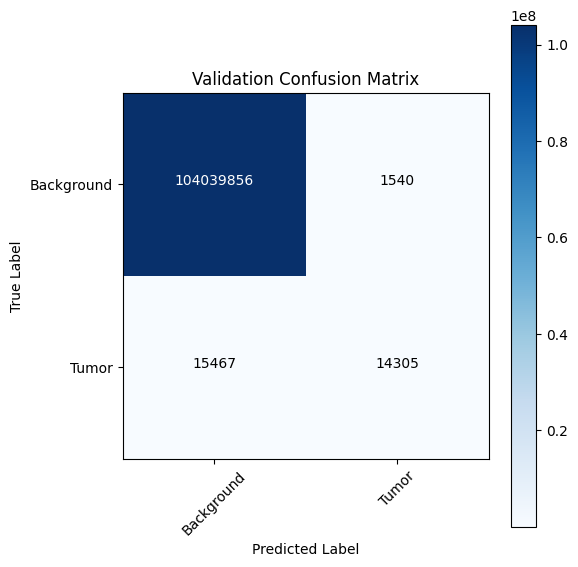

In [37]:
# Example: Compute and plot confusion matrix after validation
# (Assumes preds and labels are lists of arrays from validation loop)
import numpy as np

# Flatten predictions and labels for confusion matrix
flat_preds = np.concatenate([p.flatten() for p in preds]) > 0.5
flat_labels = np.concatenate([l.flatten() for l in labels])

plot_conf_matrix(flat_labels.astype(int), flat_preds.astype(int), class_names=["Background", "Tumor"], title="Validation Confusion Matrix")

In [38]:
# Compute Dice Score on validation set
dice_score = DiceScore()(torch.from_numpy(preds), torch.from_numpy(labels).unsqueeze(0).float())
print(f"The Val Dice Score is: {dice_score:.4f}")

# Save the trained model for inference cells below
best_path = os.path.join(BASE_DIR, "best_model.pth")
torch.save({
    'model_state_dict': model.model.state_dict(),
    'epoch': trainer.current_epoch,
}, best_path)
print(f"Model saved to: {best_path}")

The Val Dice Score is: 0.6163
Model saved to: E:\aryan\best_model.pth


In [39]:
preds = []
labels = []

for slice, label in tqdm(val_dataset):
    slice = torch.tensor(slice).float().to(device).unsqueeze(0)
    with torch.no_grad():
        pred = torch.sigmoid(model(slice))
    preds.append(pred.cpu().numpy())
    labels.append(label)
    
preds = np.array(preds)
labels = np.array(labels)

  0%|          | 0/1588 [00:00<?, ?it/s]

In [40]:
dice_score = DiceScore()(torch.from_numpy(preds), torch.from_numpy(labels).unsqueeze(0).float())
print(f"The Val Dice Score is: {dice_score}")


The Val Dice Score is: 0.6162645816802979


In [41]:
THRESHOLD = 0.5

In [42]:
import nibabel as nib
import cv2

In [43]:
# Load a CT scan from imagesTr (local path)
subject_name = "lung_010.nii"
subject_path = resolve_nii_path(IMAGES_TR_DIR, subject_name)
print(f"Loading CT from: {subject_path}")

ct = nib.load(subject_path).get_fdata() / 3071  # standardize
ct = ct[:, :, 30:]  # crop first 30 slices (noisy)
print(f"CT shape after crop: {ct.shape}")

Loading CT from: E:\aryan\imagesTr\lung_010.nii\lung_010.nii
CT shape after crop: (512, 512, 211)


In [44]:
# segmentation = []
# label = []
# scan = []

# for i in range(ct.shape[-1]):
#     slice = ct[:,:,i]
#     slice = cv2.resize(slice, (256, 256))
#     slice = torch.tensor(slice)
#     scan.append(slice)
#     slice = slice.unsqueeze(0).unsqueeze(0).float().to(device)
    
#     with torch.no_grad():
#         pred = model(slice)[0][0].cpu()
#     pred = pred > THRESHOLD
#     segmentation.append(pred)
#     label.append(segmentation)

In [45]:
import nibabel as nib
import numpy as np
import cv2

# Run inference on the loaded CT volume
segmentation_array = np.zeros_like(ct)

for i in tqdm(range(ct.shape[-1]), desc="Segmenting slices"):
    slice_ = ct[:, :, i]
    slice_resized = cv2.resize(slice_, (256, 256))
    slice_resized = torch.tensor(slice_resized).unsqueeze(0).unsqueeze(0).float().to(device)

    with torch.no_grad():
        pred = model(slice_resized)[0][0].cpu()
    pred = pred > THRESHOLD

    pred_resized = cv2.resize(pred.float().numpy(), (ct.shape[1], ct.shape[0]), interpolation=cv2.INTER_NEAREST)
    segmentation_array[:, :, i] = pred_resized

# Save segmentation as NIfTI (local path)
segmentation_nii = nib.Nifti1Image(segmentation_array, np.eye(4))
seg_save_path = os.path.join(PRED_DIR, 'predicted_segmentation.nii')
nib.save(segmentation_nii, seg_save_path)
print(f"Saved predicted segmentation: {seg_save_path}")

Segmenting slices:   0%|          | 0/211 [00:00<?, ?it/s]

Saved predicted segmentation: E:\aryan\notebook_outputs\predictions\predicted_segmentation.nii


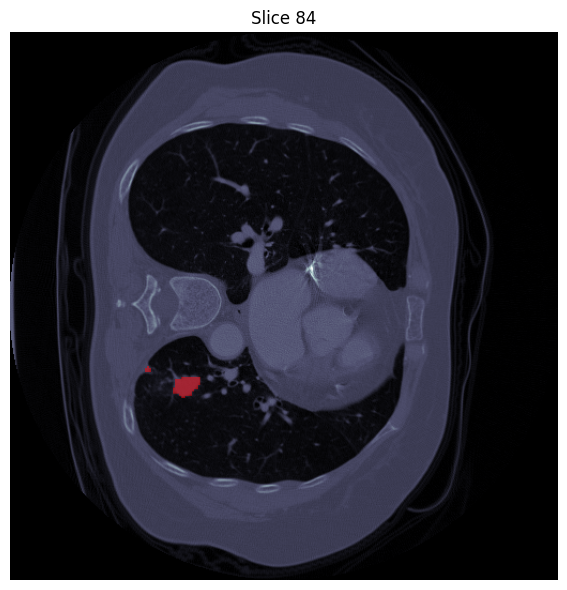

In [46]:
import numpy as np
import matplotlib.pyplot as plt

# Chọn mặt cắt cụ thể, ví dụ mặt cắt thứ 84
slice_idx = 84  # Thay đổi chỉ số mặt cắt mà bạn muốn hiển thị

# Giả sử 'ct' và 'segmentation_array' đều là các mảng 3D đã có sẵn
# 'ct' là dữ liệu CT đã chuẩn hóa
# 'segmentation_array' là kết quả phân đoạn (0: nền, 1: khu vực u)

# Vẽ mặt cắt đã chọn
fig, ax = plt.subplots(1, 1, figsize=(6, 6))  # Hiển thị 1 mặt cắt

# Hiển thị mặt cắt CT
ax.imshow(ct[:,:,slice_idx], cmap="bone")  # Đảm bảo bạn truy cập đúng phần của mảng CT

# Áp dụng mask vào mặt cắt dự đoán (dùng segmentation_array nếu bạn đã có nó)
mask = np.ma.masked_where(segmentation_array[:,:,slice_idx] == 0, segmentation_array[:,:,slice_idx])  # Áp dụng mask

# Hiển thị phần dự đoán với màu đỏ (autumn)
ax.imshow(mask, alpha=0.5, cmap="autumn")

# Thiết lập các thông số
ax.axis("off")
ax.set_title(f"Slice {slice_idx}")

# Căn chỉnh và hiển thị
plt.tight_layout()  # Căn chỉnh mặt cắt
plt.show()  # Hiển thị mặt cắt đã chọn


In [50]:
!conda install -c conda-forge ffmpeg
!pip install imageio[ffmpeg]

^C


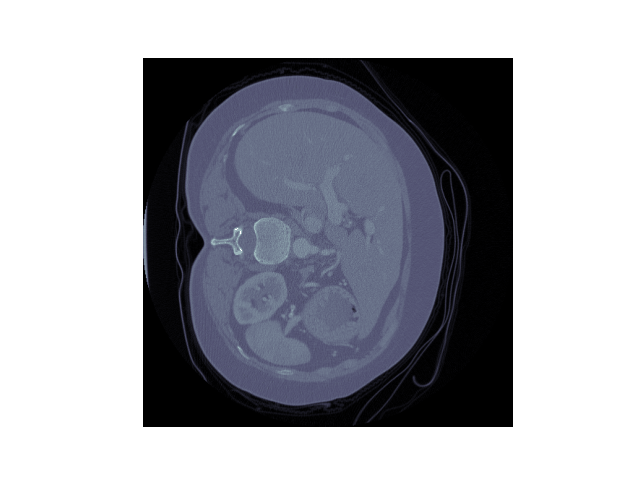

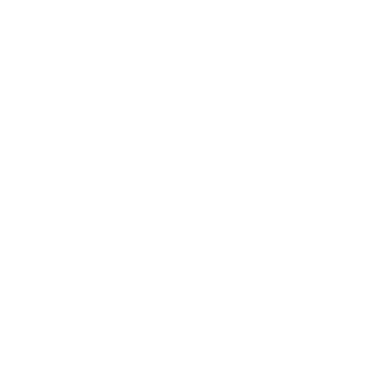

In [52]:
from celluloid import Camera
import matplotlib.pyplot as plt

fig = plt.figure()
camera = Camera(fig)
for i in range(0, len(ct[0, 0, :]), 2):
    plt.imshow(ct[:,:,i], cmap="bone")
    mask = np.ma.masked_where(segmentation_array[:,:,i] == 0, segmentation_array[:,:,i])
    plt.imshow(mask, alpha=0.5, cmap="autumn")
    plt.axis("off")
    camera.snap()

animation = camera.animate()
animation.save('segmentation.gif', writer='pillow', fps=5)

from IPython.display import Image, display
display(Image(filename='segmentation.gif'))

In [54]:
pip install imageio[ffmpeg]

Note: you may need to restart the kernel to use updated packages.


In [56]:
!pip install plotly


In [57]:
import nibabel as nib
import numpy as np

# Read predicted segmentation NIfTI (local path)
pred_seg_path = os.path.join(PRED_DIR, 'predicted_segmentation.nii')
if not os.path.exists(pred_seg_path):
    pred_seg_path = 'predicted_segmentation.nii'

nii_image = nib.load(pred_seg_path)
data = nii_image.get_fdata()

unique_labels = np.unique(data)
print("Labels in file:", unique_labels)
print("Number of labels:", len(unique_labels))

Labels in file: [0. 1.]
Number of labels: 2


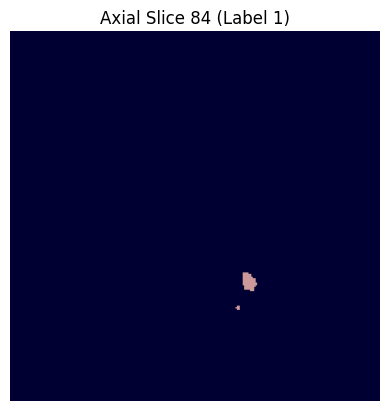

In [58]:
import nibabel as nib
import numpy as np
import matplotlib.pyplot as plt

def load_nii(file_path):
    img = nib.load(file_path)
    img_data = img.get_fdata()
    return img_data

def display_slice_with_label(img_data, slice_idx, plane='axial', label=1):
    if plane == 'axial':
        slice_img = img_data[:, :, slice_idx]
    elif plane == 'coronal':
        slice_img = img_data[:, slice_idx, :]
    elif plane == 'sagittal':
        slice_img = img_data[slice_idx, :, :]
    else:
        raise ValueError("Plane must be 'axial', 'coronal', or 'sagittal'.")

    label_slice = np.where(slice_img == label, 1, 0)

    plt.imshow(slice_img.T, cmap='gray', origin='lower')
    plt.imshow(label_slice.T, cmap='jet', alpha=0.4, origin='lower')
    plt.title(f"{plane.capitalize()} Slice {slice_idx} (Label {label})")
    plt.axis('off')
    plt.show()

# Use local path
pred_seg_path = os.path.join(PRED_DIR, 'predicted_segmentation.nii')
if not os.path.exists(pred_seg_path):
    pred_seg_path = 'predicted_segmentation.nii'

img_data = load_nii(pred_seg_path)

slice_idx = 84
plane = 'axial'
label = 1
display_slice_with_label(img_data, slice_idx, plane, label)

In [60]:
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
from mpl_toolkits.mplot3d import Axes3D
import os

# Helper to resolve .nii file path inside nested folder
def resolve_nii_path(parent_dir, folder_name):
    folder_path = os.path.join(parent_dir, folder_name)
    for f in os.listdir(folder_path):
        if f.endswith('.nii') or f.endswith('.nii.gz'):
            return os.path.join(folder_path, f)
    raise FileNotFoundError(f"No .nii file found in {folder_path}")

# Select a subject (example: 'lung_010.nii')
subject_name = 'lung_010.nii'  # Change to any available subject
imagesTr_dir = r'E:\aryan\imagesTr'
labelsTr_dir = r'E:\aryan\labelsTr'

# Get image and label paths
image_path = resolve_nii_path(imagesTr_dir, subject_name)
label_path = resolve_nii_path(labelsTr_dir, subject_name)

# Load image and label
nii_image = nib.load(image_path)
nii_label = nib.load(label_path)
image_data = nii_image.get_fdata()
label_data = nii_label.get_fdata()

# For 3D segmentation visualization, use the label (segmentation) data
segmentation_data = label_data

# Check unique labels in segmentation
unique_labels = np.unique(segmentation_data)
print("Unique labels in segmentation:", unique_labels)

# Choose labels to display (e.g., 1 for tumor, 0 for background)
label_1 = 1  # Tumor
label_0 = 0  # Background

# Get voxel coordinates for each label
x_1, y_1, z_1 = np.where(segmentation_data == label_1)  # All voxels with label 1
x_0, y_0, z_0 = np.where(segmentation_data == label_0)  # All voxels with label 0

# Print number of voxels for each label
print(f"Number of voxels with label {label_1}: {len(x_1)}")
print(f"Number of voxels with label {label_0}: {len(x_0)}")

# Print segmentation image shape
img_shape = segmentation_data.shape
print("Segmentation image shape:", img_shape)

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot background voxels (label 0) in light gray, low opacity
ax.scatter(x_0, y_0, z_0, c='gray', marker='o', s=0.5, alpha=0.1)
# Plot tumor voxels (label 1) in red, high opacity
ax.scatter(x_1, y_1, z_1, c='r', marker='o', s=0.5, alpha=1.0)

ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
plt.title(f"3D Segmentation of Label {label_1} (Tumor) from NIfTI File")
ax.set_box_aspect([1, 1, 1])
plt.show()

Unique labels in segmentation: [0. 1.]
Number of voxels with label 1: 27311
Number of voxels with label 0: 63149393
Segmentation image shape: (512, 512, 241)


KeyboardInterrupt: 

In [ ]:
# import torch
# import torch.nn as nn
# import torch.nn.functional as F
# import matplotlib.pyplot as plt

# class DoubleConv(torch.nn.Module):
#     """
#     Helper Class which implements the intermediate Convolutions for 3D
#     """
#     def __init__(self, in_channels, out_channels):
#         super().__init__()
#         self.step = torch.nn.Sequential(
#             torch.nn.Conv3d(in_channels, out_channels, 3, padding=1),
#             torch.nn.ReLU(),
#             torch.nn.Conv3d(out_channels, out_channels, 3, padding=1),
#             torch.nn.ReLU()
#         )
        
#     def forward(self, X):
#         return self.step(X)

# class UNet(torch.nn.Module):
#     """
#     This class implements a 3D UNet for the Segmentation
#     We use 3 down- and 3 UpConvolutions and two Convolutions in each step
#     """

#     def __init__(self):
#         super().__init__()
        
#         ############# DOWN #####################
#         self.layer1 = DoubleConv(1, 64)
#         self.layer2 = DoubleConv(64, 128)
#         self.layer3 = DoubleConv(128, 256)
#         self.layer4 = DoubleConv(256, 512)

#         #########################################

#         ############## UP #######################
#         self.layer5 = DoubleConv(512 + 256, 256)
#         self.layer6 = DoubleConv(256 + 128, 128)
#         self.layer7 = DoubleConv(128 + 64, 64)
#         self.layer8 = torch.nn.Conv3d(64, 1, 1)  # Output layer for 3D
#         #########################################

#         self.maxpool = torch.nn.MaxPool3d(2)  # Use MaxPool3d for 3D
#         self.adaptive_pool = torch.nn.AdaptiveMaxPool3d((None, None, None))  # Adaptive pooling

#     def forward(self, x):
        
#         ####### DownConv 1#########
#         x1 = self.layer1(x)
#         x1m = self.maxpool(x1)
#         ###########################
        
#         ####### DownConv 2#########        
#         x2 = self.layer2(x1m)
#         x2m = self.maxpool(x2)
#         ###########################

#         ####### DownConv 3#########        
#         x3 = self.layer3(x2m)
#         x3m = self.maxpool(x3)
#         ###########################
        
#         ##### Intermediate Layer ## 
#         x4 = self.layer4(x3m)
#         ###########################

#         ####### UpCONV 1#########        
#         x5 = torch.nn.Upsample(scale_factor=2, mode="trilinear")(x4)  # Use trilinear for 3D upsampling
#         x5 = torch.cat([x5, x3], dim=1)  # Skip-Connection
#         x5 = self.layer5(x5)
#         ###########################

#         ####### UpCONV 2#########        
#         x6 = torch.nn.Upsample(scale_factor=2, mode="trilinear")(x5)        
#         x6 = torch.cat([x6, x2], dim=1)  # Skip-Connection    
#         x6 = self.layer6(x6)
#         ###########################
        
#         ####### UpCONV 3#########        
#         x7 = torch.nn.Upsample(scale_factor=2, mode="trilinear")(x6)
#         x7 = torch.cat([x7, x1], dim=1)       
#         x7 = self.layer7(x7)
#         ###########################
        
#         ####### Predicted segmentation#########        
#         ret = self.layer8(x7)
#         return ret


In [ ]:
# import torch
# import torch.nn.functional as F
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# # Định nghĩa lớp GradCAM
# class GradCAM:
#     def __init__(self, model, target_layer):
#         self.model = model
#         self.target_layer = target_layer
#         self.gradient = None
#         self.activation = None
#         self._register_hooks()

#     def _register_hooks(self):
#         def save_activation(module, input, output):
#             self.activation = output

#         def save_gradient(module, grad_input, grad_output):
#             self.gradient = grad_output[0]

#         self.target_layer.register_forward_hook(save_activation)
#         self.target_layer.register_backward_hook(save_gradient)

#     def forward(self, x):
#         return self.model(x)

#     def get_cam(self, input_image, target_class=None):
#         # Tiến hành forward pass
#         output = self.forward(input_image)
        
#         if target_class is None:
#             target_class = output.argmax(dim=1).item()
        
#         # Tiến hành backward pass
#         self.model.zero_grad()
#         class_loss = output[0, target_class]
#         class_loss.backward(retain_graph=True)
        
#         gradients = self.gradient
#         activations = self.activation
        
#         # Giải phóng bộ nhớ sau khi sử dụng
#         self.gradient = None
#         self.activation = None

#         weights = torch.mean(gradients, dim=(2, 3), keepdim=True)
#         cam = torch.sum(weights * activations, dim=1)
#         cam = F.relu(cam)
        
#         cam = cam - cam.min()
#         cam = cam / cam.max()

#         return cam[0].cpu().detach().numpy()

#     def overlay_cam(self, image, cam, alpha=0.5):
#         # Resize CAM về kích thước của ảnh gốc
#         cam_resized = cv2.resize(cam, (image.shape[1], image.shape[0]))
        
#         # Chuyển ảnh gốc về RGB
#         image_rgb = cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
        
#         # Tạo heatmap từ CAM
#         heatmap = cv2.applyColorMap(np.uint8(255 * cam_resized), cv2.COLORMAP_JET)
        
#         # Chồng heatmap lên ảnh gốc
#         superimposed = heatmap * alpha + image_rgb
#         return np.uint8(superimposed)

# # Hàm để áp dụng Grad-CAM lên một bức ảnh
# def apply_grad_cam(model, image, target_layer, device='cpu'):
#     grad_cam = GradCAM(model, target_layer)
    
#     # Chuyển ảnh thành tensor và đưa lên device (GPU/CPU)
#     image_tensor = torch.tensor(image).unsqueeze(0).unsqueeze(0).float().to(device)  # Thêm batch và channel dimensions
    
#     # Lấy Grad-CAM từ ảnh
#     with torch.no_grad():  # Giảm tiêu thụ bộ nhớ
#         cam = grad_cam.get_cam(image_tensor)
    
#     # Overlay CAM lên ảnh gốc
#     image_with_cam = grad_cam.overlay_cam(image, cam)
    
#     return image_with_cam

# # Ví dụ sử dụng:
# slice_idx = 84  # Chọn mặt cắt của ảnh CT
# image = ct[:, :, slice_idx]  # Chọn mặt cắt từ ảnh CT

# # Giả sử bạn đã khởi tạo model TumorSegmentation
# model = TumorSegmentation()
# device = 'cuda' if torch.cuda.is_available() else 'cpu'
# model.to(device)

# # Truy cập lớp layer4 bên trong UNet
# target_layer = model.model.layer4  # Đảm bảo bạn đã khởi tạo model và target_layer

# # Áp dụng Grad-CAM
# image_with_cam = apply_grad_cam(model, image_resized, target_layer, device=device)

# # Hiển thị kết quả
# plt.figure(figsize=(10, 8))
# plt.imshow(image_with_cam)
# plt.title("Grad-CAM Overlay")
# plt.axis('off')
# plt.show()


In [ ]:
# class GradCAM:
#     def __init__(self, model, target_layer):
#         self.model = model
#         self.target_layer = target_layer
#         self.hooks = []
#         self._register_hook()

#     def _register_hook(self):
#         def forward_hook(module, input, output):
#             self.activations = output
#         def backward_hook(module, grad_input, grad_output):
#             self.gradients = grad_output[0]

#         self.hooks.append(self.target_layer.register_forward_hook(forward_hook))
#         self.hooks.append(self.target_layer.register_backward_hook(backward_hook))
    
#     def remove_hooks(self):
#         for hook in self.hooks:
#             hook.remove()

#     def __call__(self, input_tensor, threshold=0.5):
#         self.model.eval()
#         self.model.zero_grad()

#         output = self.model(input_tensor)  # Get the output from the model
#         output = torch.sigmoid(output)  # Use sigmoid for binary segmentation

#         # Backpropagate the gradients for each pixel
#         output.backward(gradient=torch.ones_like(output), retain_graph=True)

#         gradients = self.gradients.detach().cpu().numpy()[0]
#         activations = self.activations.detach().cpu().numpy()[0]

#         # Get the weights for each channel (pixel)
#         weights = np.mean(gradients, axis=(1, 2))
#         cam = np.sum(weights[:, np.newaxis, np.newaxis] * activations, axis=0)

#         cam = np.maximum(cam, 0)  # Ensure all negative values are set to zero
#         cam = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]))  # Resize to match input size
#         cam = cam - np.min(cam)  # Normalize to [0, 1]
#         cam = cam / np.max(cam)  # Normalize to [0, 1]

#         return cam


In [ ]:
# import cv2
# import numpy as np
# import matplotlib.pyplot as plt

# def display_gradcam(img, grad_cam, alpha=0.4):
#     # Convert grayscale image to RGB if necessary
#     if len(img.shape) == 2:  # If img is grayscale
#         img = np.stack([img] * 3, axis=-1)  # Convert to (height, width, 3)
    
#     # Apply the heatmap
#     heatmap = cv2.applyColorMap(np.uint8(255 * grad_cam), cv2.COLORMAP_JET)
#     heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)  # Convert heatmap to RGB
    
#     # Superimpose heatmap on the original image
#     superimposed_img = heatmap * alpha + img
#     superimposed_img = superimposed_img / np.max(superimposed_img)  # Normalize to 0-1 range
    
#     # Plot the results
#     plt.figure(figsize=(10, 10))
    
#     # Original CT Image
#     plt.subplot(131)
#     plt.imshow(img)
#     plt.title("Original CT Image")
#     plt.axis('off')
    
#     # Grad-CAM Heatmap
#     plt.subplot(132)
#     plt.imshow(grad_cam, cmap='jet', alpha=0.6)
#     plt.title("Grad-CAM Heatmap")
#     plt.axis('off')
    
#     # Superimposed Grad-CAM
#     plt.subplot(133)
#     plt.imshow(superimposed_img)
#     plt.title("Superimposed Grad-CAM")
#     plt.colorbar(ticks=[0, 0.5, 1]).set_ticklabels(['Low Importance', 'Medium Importance', 'High Importance'])
#     plt.axis('off')
    
#     plt.tight_layout()
#     plt.show()


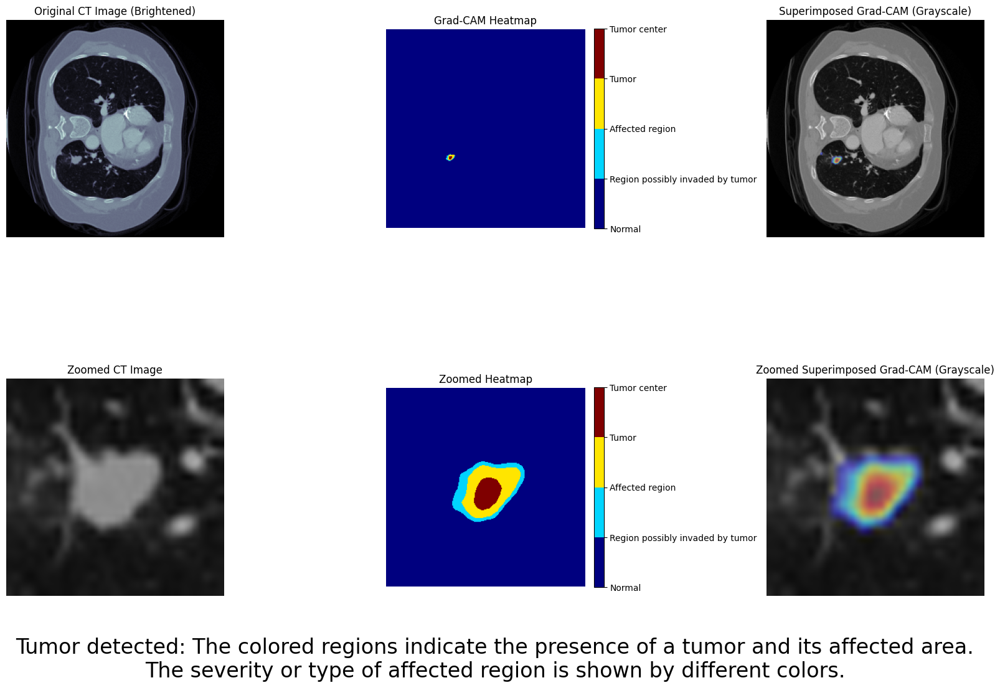

In [64]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import torch

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.hooks = []
        self._register_hook()

    def _register_hook(self):
        def forward_hook(module, input, output):
            self.activations = output
        def backward_hook(module, grad_input, grad_output):
            self.gradients = grad_output[0]

        self.hooks.append(self.target_layer.register_forward_hook(forward_hook))
        self.hooks.append(self.target_layer.register_backward_hook(backward_hook))
    
    def remove_hooks(self):
        for hook in self.hooks:
            hook.remove()

    def __call__(self, input_tensor, threshold=0.5):
        self.model.eval()
        self.model.zero_grad()

        output = self.model(input_tensor)  # Get the output from the model
        output = torch.sigmoid(output)  # Use sigmoid for binary segmentation

        # Backpropagate the gradients for each pixel
        output.backward(gradient=torch.ones_like(output), retain_graph=True)

        gradients = self.gradients.detach().cpu().numpy()[0]
        activations = self.activations.detach().cpu().numpy()[0]

        # Get the weights for each channel (pixel)
        weights = np.mean(gradients, axis=(1, 2))
        cam = np.sum(weights[:, np.newaxis, np.newaxis] * activations, axis=0)

        cam = np.maximum(cam, 0)  # Ensure all negative values are set to zero
        cam = cv2.resize(cam, (input_tensor.shape[3], input_tensor.shape[2]), interpolation=cv2.INTER_LINEAR)
        if np.max(cam) > 0:
            cam = cam / np.max(cam)  # Normalize to [0, 1]

        # Scale to [0, 10] for better threshold visualization
        cam = cam * 10
        return cam

def get_detailed_explanation(pred_label):
    explanations = {
        0: {
            "symptoms": "No tumor detected."
        },
        1: {
            "symptoms": (
                "Tumor detected: The colored regions indicate the presence of a tumor and its affected area. "
                "The severity or type of affected region is shown by different colors."
            )
        },
    }
    return explanations.get(pred_label, {"symptoms": "Unknown label."})

def display_gradcam(img, grad_cam, pred_label, alpha=0.4, zoom_factor=2):
    # Brighten the Original CT Image
    img = img - np.min(img)  # Normalize to [0, 1]
    img = img / np.max(img)
    img = np.clip(img * 1.5, 0, 1)  # Brighten the image

    # Convert grayscale image to RGB for blending
    img_gray = np.stack([img] * 3, axis=-1)  # Convert to grayscale for consistent blending

    # Apply the heatmap only where Grad-CAM > 0
    heatmap = cv2.applyColorMap(np.uint8(255 * grad_cam / 10), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # Mask out background (Grad-CAM == 0)
    heatmap[grad_cam <= 0] = img_gray[grad_cam <= 0] * 255  # Use grayscale for background

    # Superimpose heatmap on the grayscale original image
    superimposed_img = (heatmap / 255.0 * alpha + img_gray * (1 - alpha))  # Blend heatmap with gray image
    superimposed_img = np.clip(superimposed_img, 0, 1)  # Ensure the values are within [0, 1]

    # Calculate bounding box for the tumor region from Grad-CAM
    threshold = 2  # Threshold for activation
    tumor_region = grad_cam > threshold
    coords = np.argwhere(tumor_region)
    if coords.size > 0:
        y_min, x_min = coords.min(axis=0)
        y_max, x_max = coords.max(axis=0)

        # Expand bounding box for better visualization
        y_min = max(0, y_min - 10)
        y_max = min(grad_cam.shape[0], y_max + 10)
        x_min = max(0, x_min - 10)
        x_max = min(grad_cam.shape[1], x_max + 10)

        # Crop and resize to zoom in on the tumor region
        img_zoomed = cv2.resize(img_gray[y_min:y_max, x_min:x_max], (256, 256), interpolation=cv2.INTER_CUBIC)  # Improved interpolation
        heatmap_zoomed = cv2.resize(grad_cam[y_min:y_max, x_min:x_max], (256, 256), interpolation=cv2.INTER_CUBIC)
        superimposed_zoomed = cv2.resize(superimposed_img[y_min:y_max, x_min:x_max], (256, 256), interpolation=cv2.INTER_CUBIC)
    else:
        img_zoomed = cv2.resize(img_gray, (256, 256), interpolation=cv2.INTER_CUBIC)
        heatmap_zoomed = cv2.resize(grad_cam, (256, 256), interpolation=cv2.INTER_CUBIC)
        superimposed_zoomed = cv2.resize(superimposed_img, (256, 256), interpolation=cv2.INTER_CUBIC)

    # Set up colorbar boundaries and explanations
    bounds = [0, 2, 4, 8, 10]
    labels = ['Normal',
    'Region possibly invaded by tumor',
    'Affected region',
    'Tumor',
    'Tumor center']
    cmap = plt.cm.jet
    cmap = plt.cm.jet
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    # Get detailed explanation for the prediction label
    explanation = get_detailed_explanation(pred_label)

    # Plot the results
    fig, axes = plt.subplots(2, 3, figsize=(16, 12))

    # Original CT Image
    axes[0, 0].imshow(img, cmap="bone")
    axes[0, 0].set_title("Original CT Image (Brightened)")
    axes[0, 0].axis('off')

    # Grad-CAM Heatmap with Colorbar
    im = axes[0, 1].imshow(grad_cam, cmap=cmap, norm=norm)
    axes[0, 1].set_title("Grad-CAM Heatmap")
    axes[0, 1].axis('off')

    # Add colorbar with labels
    cbar = fig.colorbar(im, ax=axes[0, 1], ticks=bounds, orientation="vertical", fraction=0.046, pad=0.04)
    cbar.ax.set_yticklabels(labels)

    # Superimposed Grad-CAM
    axes[0, 2].imshow(superimposed_img)
    axes[0, 2].set_title("Superimposed Grad-CAM (Grayscale)")
    axes[0, 2].axis('off')

    # Zoomed CT Image
    axes[1, 0].imshow(img_zoomed, cmap="bone")
    axes[1, 0].set_title("Zoomed CT Image")
    axes[1, 0].axis('off')

    # Zoomed Grad-CAM Heatmap
    im_zoom = axes[1, 1].imshow(heatmap_zoomed, cmap=cmap, norm=norm)
    axes[1, 1].set_title("Zoomed Heatmap")
    axes[1, 1].axis('off')

    # Add colorbar for Zoomed Heatmap
    cbar_zoom = fig.colorbar(im_zoom, ax=axes[1, 1], ticks=bounds, orientation="vertical", fraction=0.046, pad=0.04)
    cbar_zoom.ax.set_yticklabels(labels)

    # Zoomed Superimposed Grad-CAM
    axes[1, 2].imshow(superimposed_zoomed)
    axes[1, 2].set_title("Zoomed Superimposed Grad-CAM (Grayscale)")
    axes[1, 2].axis('off')

    # Display the detailed explanation text
    plt.figtext(0.5, 0.01, explanation.get("symptoms", ""), wrap=True, horizontalalignment='center', fontsize=24)

    plt.tight_layout()
    plt.show()

# Usage example
target_layer = model.model.layer8  # Adjust as necessary
gradcam = GradCAM(model, target_layer)
selected_slice_idx = 84  # Specify slice index
slice_resized = ct[:, :, selected_slice_idx]
slice_resized = cv2.resize(slice_resized, (256, 256))
input_tensor = torch.tensor(slice_resized).unsqueeze(0).unsqueeze(0).float().to(device)

cam = gradcam(input_tensor)
display_gradcam(slice_resized, cam, pred_label=1, alpha=0.4)


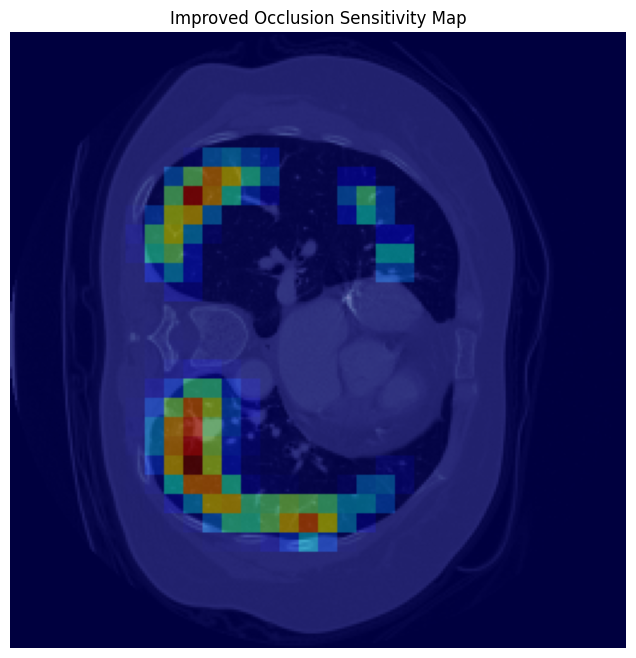

In [65]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import cv2

class ImprovedOcclusionSensitivity:
    def __init__(self, model, device='cuda'):
        self.model = model.to(device).eval()
        self.device = device

    def explain(self, image, patch_size=16, stride=8):
        """
        Tính Occlusion Sensitivity với các patch size và stride linh hoạt.
        """
        height, width = image.shape
        sensitivity_map = np.zeros((height, width), dtype=np.float32)
        image_tensor = torch.tensor(image).unsqueeze(0).unsqueeze(0).float().to(self.device)

        # Dự đoán ban đầu (original output)
        with torch.no_grad():
            original_output = torch.sigmoid(self.model(image_tensor)).detach().cpu().numpy().squeeze()

        # Duyệt qua từng ô vuông (patch)
        for y in range(0, height, stride):
            for x in range(0, width, stride):
                occluded_image = image.copy()
                occluded_image[y:y+patch_size, x:x+patch_size] = 0  # Che ô vuông bằng giá trị 0

                # Chuyển occluded image thành tensor
                occluded_tensor = torch.tensor(occluded_image).unsqueeze(0).unsqueeze(0).float().to(self.device)

                # Dự đoán với vùng che
                with torch.no_grad():
                    occluded_output = torch.sigmoid(self.model(occluded_tensor)).detach().cpu().numpy().squeeze()

                # Đo sự thay đổi dựa trên chênh lệch chuẩn hóa
                change = np.mean(np.abs(original_output - occluded_output))

                # Ghi giá trị vào sensitivity map
                sensitivity_map[y:y+patch_size, x:x+patch_size] += change

        # Normalize map
        sensitivity_map = np.maximum(sensitivity_map, 0)
        sensitivity_map /= np.max(sensitivity_map)
        return sensitivity_map

    def visualize(self, image, sensitivity_map, alpha=0.5):
        """
        Hiển thị Occlusion Sensitivity map overlay lên ảnh gốc.
        """
        fig, ax = plt.subplots(1, 1, figsize=(8, 8))
        ax.imshow(image, cmap='bone')
        ax.imshow(sensitivity_map, cmap='jet', alpha=alpha)
        ax.set_title("Improved Occlusion Sensitivity Map")
        ax.axis("off")
        plt.show()


# --- Sử dụng ImprovedOcclusionSensitivity ---
occlusion_explainer = ImprovedOcclusionSensitivity(model, device=device)

# Chọn một lát cắt CT cụ thể
slice_idx = 84  # Lát cắt thứ 84
ct_slice = ct[:, :, slice_idx]
slice_resized = cv2.resize(ct_slice, (256, 256))

# Thử nghiệm với patch_size và stride mới
patch_size = 16  # Tăng kích thước patch
stride = 8     # Tăng stride để tránh nhiễu

# Tính Occlusion Sensitivity
occlusion_map = occlusion_explainer.explain(slice_resized, patch_size=patch_size, stride=stride)

# Hiển thị kết quả
occlusion_explainer.visualize(slice_resized, occlusion_map, alpha=0.5)


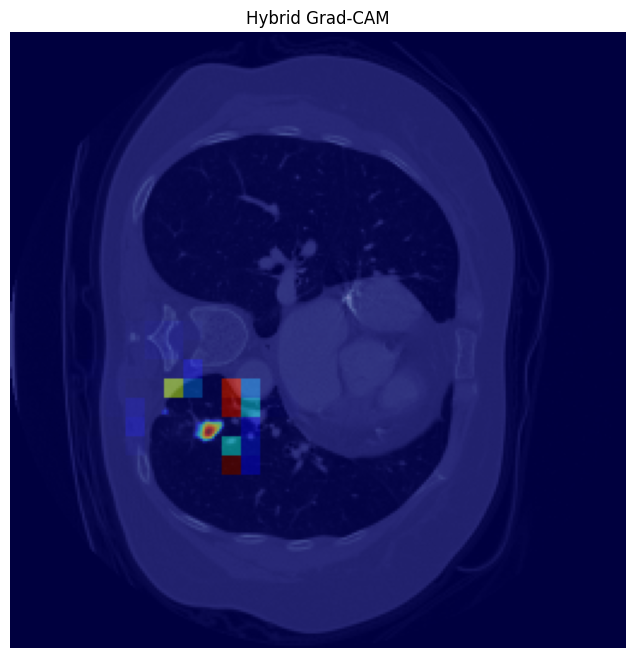

In [66]:
import torch
import torch.nn.functional as F
import numpy as np
import cv2
import matplotlib.pyplot as plt

class HybridGradCAM:
    def __init__(self, model, target_layer, device='cuda'):
        """
        Hybrid Grad-CAM kết hợp Grad-CAM và Occlusion Sensitivity cho bài toán segmentation.
        model: Mô hình segmentation (binary).
        target_layer: Lớp mà chúng ta muốn hook (thường là convolution cuối).
        device: Thiết bị ('cuda' hoặc 'cpu').
        """
        self.model = model.to(device).eval()
        self.device = device
        self.target_layer = target_layer
        
        # Biến lưu activations & gradients
        self.activations = None
        self.gradients = None
        
        # Danh sách hooks để tiện remove về sau
        self.hooks = []
        self._register_hooks()

    def _register_hooks(self):
        """
        Đăng ký hooks cho target_layer để lấy activation (forward) & gradient (backward).
        """
        def forward_hook(module, input, output):
            # output shape: (B, C, H', W') - feature map
            self.activations = output

        def backward_hook(module, grad_input, grad_output):
            # grad_output[0] shape: (B, C, H', W') - gradient wrt. output of target_layer
            self.gradients = grad_output[0]

        fwd_hook = self.target_layer.register_forward_hook(forward_hook)
        bwd_hook = self.target_layer.register_backward_hook(backward_hook)
        self.hooks.extend([fwd_hook, bwd_hook])

    def remove_hooks(self):
        """
        Xóa hooks sau khi sử dụng (tránh xung đột memory).
        """
        for hook in self.hooks:
            hook.remove()
        self.hooks = []

    def calculate_grad_cam(self, input_tensor):
        """
        Tính Grad-CAM cho một tensor đầu vào.
        
        input_tensor shape: (B, 1, H, W) - CT slice sau khi tiền xử lý, đưa lên GPU.
        Trả về: grad_cam map shape (H, W).
        """
        # Xóa gradient cũ
        self.model.zero_grad()
        
        # Forward
        output = self.model(input_tensor)   # output shape: (B, 1, H, W)
        output = torch.sigmoid(output)      # sigmoid cho binary segmentation

        # Lấy trung bình mask để backprop 1 giá trị, tránh shape mismatch
        loss_value = output.mean()
        loss_value.backward(retain_graph=True)

        # Lấy gradient & activation từ hooks
        gradients = self.gradients.detach().cpu().numpy()[0]   # (C, H', W')
        activations = self.activations.detach().cpu().numpy()[0]  # (C, H', W')

        # Tính trọng số theo kênh: trung bình grad trên không gian H'W'
        weights = np.mean(gradients, axis=(1, 2))  # shape (C,)

        # Weighted sum các activation
        grad_cam = np.zeros_like(activations[0], dtype=np.float32)  # shape (H', W')
        for i, w in enumerate(weights):
            grad_cam += w * activations[i, :, :]

        # ReLU
        grad_cam = np.maximum(grad_cam, 0)

        # Resize về kích thước đầu vào (H, W)
        _, _, h, w = input_tensor.shape
        grad_cam = cv2.resize(grad_cam, (w, h), interpolation=cv2.INTER_LINEAR)

        # Chuẩn hóa [0..1]
        if grad_cam.max() > 0:
            grad_cam = grad_cam / grad_cam.max()

        return grad_cam

    def calculate_occlusion_sensitivity(self, input_image, patch_size=16, stride=8):
        """
        Tính Occlusion Sensitivity bằng cách che các vùng ảnh (2D).
        input_image shape: (H, W) - numpy array.
        Trả về: sensitivity_map shape (H, W).
        """
        # Chuyển input_image thành tensor
        input_tensor = torch.tensor(input_image).unsqueeze(0).unsqueeze(0).float().to(self.device)
        with torch.no_grad():
            original_output = torch.sigmoid(self.model(input_tensor)).cpu().numpy().squeeze()

        height, width = input_image.shape
        sensitivity_map = np.zeros((height, width), dtype=np.float32)

        # Duyệt qua các vùng ảnh
        for y in range(0, height, stride):
            for x in range(0, width, stride):
                # Copy ảnh gốc và che patch
                occluded_image = input_image.copy()
                occluded_image[y:y+patch_size, x:x+patch_size] = 0  # hoặc np.mean(input_image) v.v.

                # Forward mô hình với ảnh đã occlude
                occluded_tensor = torch.tensor(occluded_image).unsqueeze(0).unsqueeze(0).float().to(self.device)
                with torch.no_grad():
                    occluded_output = torch.sigmoid(self.model(occluded_tensor)).cpu().numpy().squeeze()

                # Tính mức độ thay đổi theo trung bình mask
                change = np.mean(original_output) - np.mean(occluded_output)
                sensitivity_map[y:y+patch_size, x:x+patch_size] += change

        # ReLU sensitivity (loại bỏ giá trị âm nếu có)
        sensitivity_map = np.maximum(sensitivity_map, 0)

        # Chuẩn hóa về [0..1] nếu max > 0
        max_val = np.max(sensitivity_map)
        if max_val > 0:
            sensitivity_map /= max_val

        return sensitivity_map

    def explain(self, input_image, patch_size=16, stride=8):
        """
        Kết hợp Grad-CAM và Occlusion Sensitivity để tạo Hybrid Map.
        input_image shape: (H, W) - numpy array, ảnh CT slice 2D đã resize.
        patch_size, stride: tham số cho occlusion.
        Trả về: hybrid_map shape (H, W).
        """
        # Chuyển input_image -> (B=1, 1, H, W)
        input_tensor = torch.tensor(input_image).unsqueeze(0).unsqueeze(0).float().to(self.device)

        # Tính Grad-CAM
        grad_cam = self.calculate_grad_cam(input_tensor)  # shape (H, W)

        # Tính Occlusion Sensitivity
        occlusion_map = self.calculate_occlusion_sensitivity(input_image, patch_size, stride)  # (H, W)

        # Trung bình cộng
        hybrid_map = (grad_cam + occlusion_map) / 2.0
        return hybrid_map

    def visualize(self, input_image, hybrid_map, alpha=0.5):
        """
        Hiển thị Hybrid Grad-CAM overlay lên ảnh gốc.
        input_image, hybrid_map shape: (H, W)
        """
        # Chuẩn hóa hybrid_map [0..1]
        hybrid_overlay = np.maximum(hybrid_map, 0)
        if hybrid_overlay.max() > 0:
            hybrid_overlay /= hybrid_overlay.max()

        plt.figure(figsize=(8, 8))
        plt.imshow(input_image, cmap='bone')
        plt.imshow(hybrid_overlay, cmap='jet', alpha=alpha)
        plt.title("Hybrid Grad-CAM")
        plt.axis('off')
        plt.show()

# -------------------------------
# Cách sử dụng HybridGradCAM
# -------------------------------

# Giả sử bạn đã có model segmentation tên `model`
# và định nghĩa `target_layer` là lớp cuối của backbone, thí dụ:
target_layer = model.model.layer8  # Tùy thuộc cấu trúc model

# Khởi tạo Hybrid Grad-CAM
#device = 'cuda' hoặc 'cpu'
hybrid_explainer = HybridGradCAM(model, target_layer, device='cuda')

# Chọn lát cắt CT (slice_idx)
ct_slice = ct[:, :, slice_idx]  # shape (H, W)
slice_resized = cv2.resize(ct_slice, (256, 256))

# Tạo hybrid map
hybrid_map = hybrid_explainer.explain(slice_resized, patch_size=16, stride=8)

# Hiển thị
hybrid_explainer.visualize(slice_resized, hybrid_map, alpha=0.5)

# Khi xong nên remove hooks
#hybrid_explainer.remove_hooks()


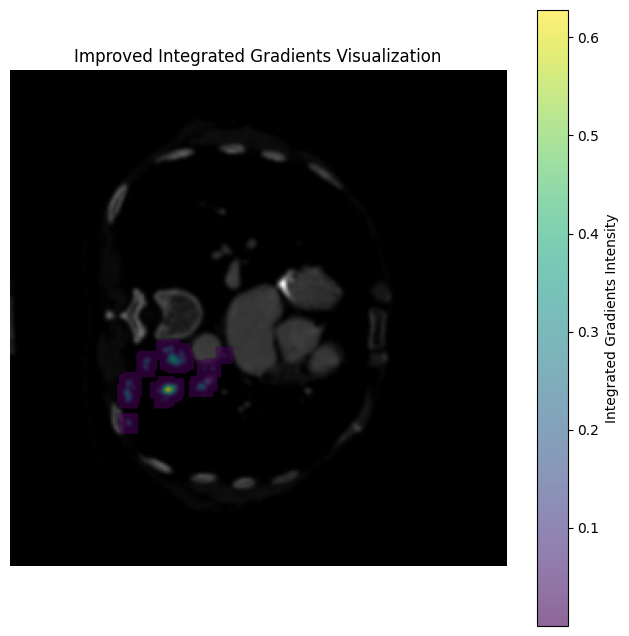

In [67]:
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

class IntegratedGradients:
    def __init__(self, model, device='cuda'):
        """
        Integrated Gradients Explainer cho mô hình segmentation.
        """
        self.model = model.to(device).eval()
        self.device = device

    def explain(self, image, steps=50, threshold=0.2):
        """
        Tính Integrated Gradients với baseline là ảnh mờ Gaussian và lọc ngưỡng.
        """
        # Chuyển ảnh thành tensor
        input_tensor = torch.tensor(image).unsqueeze(0).unsqueeze(0).float().to(self.device)

        # Tạo baseline Gaussian Blur
        baseline = gaussian_filter(image, sigma=5)
        baseline_tensor = torch.tensor(baseline).unsqueeze(0).unsqueeze(0).float().to(self.device)

        # Tạo các điểm trung gian giữa baseline và input
        scaled_inputs = torch.stack([
            baseline_tensor + (float(i) / steps) * (input_tensor - baseline_tensor)
            for i in range(steps + 1)
        ]).to(self.device)

        # Tính gradient cho từng bước
        gradients = torch.zeros_like(input_tensor).to(self.device)
        for scaled_input in scaled_inputs:
            scaled_input.requires_grad = True
            output = torch.sigmoid(self.model(scaled_input)).mean()  # Tính giá trị trung bình
            output.backward()
            gradients += scaled_input.grad.detach()
            scaled_input.requires_grad = False  # Reset requires_grad

        # Tính trung bình gradient và tích hợp
        avg_gradients = gradients / steps
        integrated_gradients = (input_tensor - baseline_tensor) * avg_gradients
        integrated_gradients = integrated_gradients.cpu().numpy()[0, 0]

        # Chuẩn hóa và lọc ngưỡng
        integrated_gradients = np.maximum(integrated_gradients, 0)
        integrated_gradients /= np.max(integrated_gradients)
        integrated_gradients[integrated_gradients < threshold] = 0  # Lọc ngưỡng

        # Làm mịn bản đồ IG
        smoothed_ig_map = gaussian_filter(integrated_gradients, sigma=1)
        return smoothed_ig_map

    def visualize(self, image, ig_map, colormap='viridis', alpha=0.6):
        """
        Hiển thị bản đồ Integrated Gradients overlay trên ảnh gốc với cải tiến.
        """
        # Làm mờ ảnh gốc để vùng IG nổi bật hơn
        image = np.clip(image, 0, 1)
        background = cv2.GaussianBlur(image, (5, 5), sigmaX=1)

        # Tạo bản đồ IG tô màu trên vùng có giá trị cao
        masked_ig = np.ma.masked_where(ig_map == 0, ig_map)  # Ẩn giá trị thấp

        # Hiển thị ảnh
        plt.figure(figsize=(8, 8))
        plt.imshow(background, cmap='gray')  # Ảnh gốc làm nền
        plt.imshow(masked_ig, cmap=colormap, alpha=alpha)  # Overlay IG
        plt.colorbar(label="Integrated Gradients Intensity")  # Thêm colorbar
        plt.title("Improved Integrated Gradients Visualization")
        plt.axis('off')
        plt.show()



# --- Sử dụng Integrated Gradients ---
ig_explainer = IntegratedGradients(model, device=device)

# Chọn mặt cắt cụ thể
slice_idx = 84  # Chọn chỉ số lát cắt
ct_slice = ct[:, :, slice_idx]
slice_resized = cv2.resize(ct_slice, (256, 256))

# Chạy Integrated Gradients
ig_map = ig_explainer.explain(slice_resized, steps=200, threshold=0.2)

# Hiển thị kết quả với colormap 'jet'
ig_explainer.visualize(slice_resized, ig_map, colormap='viridis', alpha=0.6)


Calculating Grad-CAM for each slice...


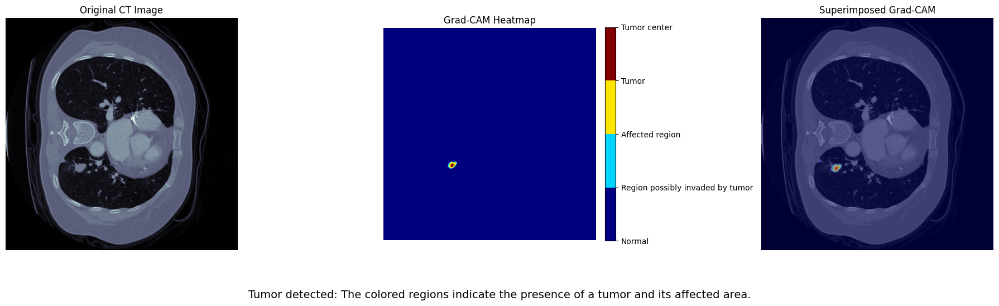

Loading ground truth...
Calculating IoU...
IoU: 0.6903


In [68]:
def get_detailed_explanation(pred_label):
    explanations = {
        0: {"symptoms": "No tumor detected."},
        1: {"symptoms": "Tumor detected: The colored regions indicate the presence of a tumor and its affected area."}
    }
    return explanations.get(pred_label, {})

def display_gradcam(img, grad_cam, pred_label, alpha=0.4):
    """
    Display Grad-CAM, Superimposed Grad-CAM, and the explanation.
    """
    img_norm = img - np.min(img)
    if np.max(img_norm) > 0:
        img_norm = img_norm / np.max(img_norm)
    img_norm = np.clip(img_norm * 1.5, 0, 1)

    img_gray = np.stack([img_norm] * 3, axis=-1)
    heatmap = cv2.applyColorMap(np.uint8(255 * grad_cam / 10), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    superimposed_img = (heatmap / 255.0 * alpha + img_gray * (1 - alpha))
    superimposed_img = np.clip(superimposed_img, 0, 1)

    explanation = get_detailed_explanation(pred_label)

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    bounds = [0, 2, 4, 8, 10]
    labels = [
        'Normal',
        'Region possibly invaded by tumor',
        'Affected region',
        'Tumor',
        'Tumor center'
    ]
    cmap = plt.cm.jet
    norm = mcolors.BoundaryNorm(bounds, cmap.N)

    # Original Image
    axes[0].imshow(img_norm, cmap="bone")
    axes[0].set_title("Original CT Image")
    axes[0].axis('off')

    # Grad-CAM Heatmap
    im = axes[1].imshow(grad_cam, cmap=cmap, norm=norm)
    axes[1].set_title("Grad-CAM Heatmap")
    axes[1].axis('off')
    cbar = fig.colorbar(im, ax=axes[1], ticks=bounds, orientation="vertical", fraction=0.046, pad=0.04)
    cbar.ax.set_yticklabels(labels)

    # Superimposed Grad-CAM
    axes[2].imshow(superimposed_img)
    axes[2].set_title("Superimposed Grad-CAM")
    axes[2].axis('off')

    plt.figtext(0.5, 0.01, explanation.get("symptoms", ""), wrap=True, horizontalalignment='center', fontsize=14)
    plt.tight_layout()
    plt.show()

# -------------------- Apply Grad-CAM to the entire CT scan --------------------
target_layer = model.model.layer8  
gradcam = GradCAM(model, target_layer)

H, W, D = ct.shape
grad_cam_volume = np.zeros((H, W, D), dtype=np.float32)

print("Calculating Grad-CAM for each slice...")
for i in range(D):
    slice_ = ct[:, :, i]
    slice_resized = cv2.resize(slice_, (256, 256))
    input_tensor = torch.tensor(slice_resized).unsqueeze(0).unsqueeze(0).float().to(device)
    cam = gradcam(input_tensor)  
    cam_resized = cv2.resize(cam, (W, H), interpolation=cv2.INTER_LINEAR)
    grad_cam_volume[:, :, i] = cam_resized

# Display a Grad-CAM slice
slice_idx = 84
img_slice = ct[:, :, slice_idx]
cam_slice = grad_cam_volume[:, :, slice_idx]
display_gradcam(img_slice, cam_slice, pred_label=1, alpha=0.4)

# -------------------- Calculate IoU --------------------
print("Loading ground truth...")
gt_path = resolve_nii_path(LABELS_TR_DIR, "lung_010.nii")
gt_nii = nib.load(gt_path)
gt_array = gt_nii.get_fdata()

# Crop ground truth to match
gt_array = gt_array[:, :, 30:]
gt_binary = (gt_array > 0.5).astype(np.float32)
pred_binary = (grad_cam_volume > 2.0).astype(np.float32)  # Grad-CAM threshold

# Calculate IoU
print("Calculating IoU...")
intersection = (pred_binary * gt_binary).sum()
union = ((pred_binary + gt_binary) > 0).sum()
iou = intersection / union if union > 0 else 0.0
print(f"IoU: {iou:.4f}")

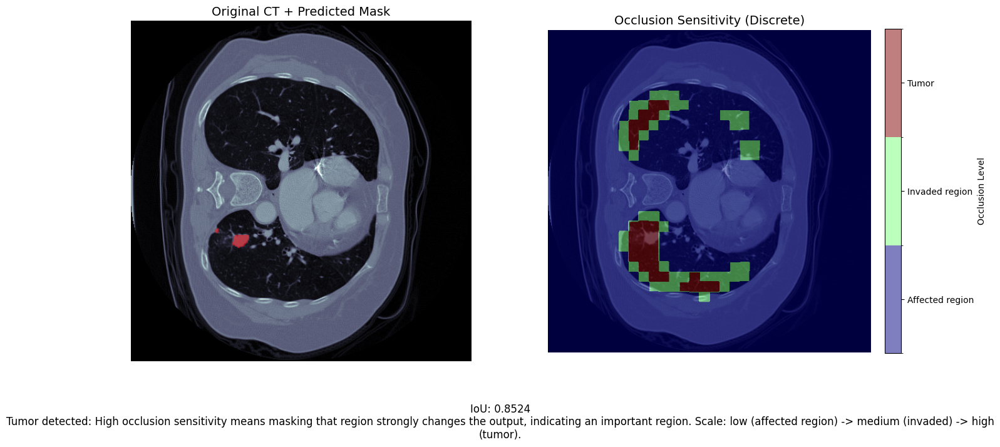

In [69]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cv2

class ImprovedOcclusionSensitivity:
    def __init__(self, model, device='cuda'):
        self.model = model.to(device).eval()
        self.device = device

    def explain(self, image, patch_size=16, stride=8):
        """
        Compute Occlusion Sensitivity for a single slice (image: H,W).
        Returns: sensitivity_map and original_output (initial predicted mask).
        """
        height, width = image.shape
        sensitivity_map = np.zeros((height, width), dtype=np.float32)
        image_tensor = torch.tensor(image).unsqueeze(0).unsqueeze(0).float().to(self.device)

        # Initial prediction (original_output)
        with torch.no_grad():
            original_output = torch.sigmoid(self.model(image_tensor)).cpu().numpy().squeeze()

        # Slide over each patch
        for y in range(0, height, stride):
            for x in range(0, width, stride):
                occluded_image = image.copy()
                occluded_image[y:y+patch_size, x:x+patch_size] = 0

                occluded_tensor = torch.tensor(occluded_image).unsqueeze(0).unsqueeze(0).float().to(self.device)
                with torch.no_grad():
                    occluded_output = torch.sigmoid(self.model(occluded_tensor)).cpu().numpy().squeeze()

                # Measure the change
                change = np.mean(np.abs(original_output - occluded_output))
                sensitivity_map[y:y+patch_size, x:x+patch_size] += change

        # Normalize map
        sensitivity_map = np.maximum(sensitivity_map, 0)
        if np.max(sensitivity_map) > 0:
            sensitivity_map /= np.max(sensitivity_map)
        return sensitivity_map, original_output

    def visualize(self, img_slice, occlusion_map_slice, pred_binary_slice, gt_slice=None, pred_label=1, alpha=0.5):
        """
        Display the Occlusion Sensitivity map for a single slice.
        Uses a discrete scale similar to IG:
        0 - 0.2: Affected region
        0.2 - 0.5: Invaded region
        0.5 - 1.0: Tumor

        Shows 2 images:
        - Left: CT + Predicted Mask
        - Right: CT + Occlusion Map (discrete)

        Calculates IoU if gt_slice is provided.
        """

        # Prepare the original image
        img_norm = img_slice - np.min(img_slice)
        if np.max(img_norm) > 0:
            img_norm /= np.max(img_norm)
        img_norm = np.clip(img_norm * 1.5, 0, 1)

        # Calculate IoU if ground truth is available
        iou = None
        if gt_slice is not None:
            gt_binary = (gt_slice > 0.5).astype(np.float32)
            intersection = (pred_binary_slice * gt_binary).sum()
            union = (pred_binary_slice + gt_binary).clip(0, 1).sum()
            iou = intersection / union if union > 0 else 0.0

        # Label explanation function
        def get_detailed_explanation(pred_label):
            explanations = {
                1: {
                    "symptoms": "No tumor detected."
                },
                0: {
                    "symptoms": (
                        "Tumor detected: High occlusion sensitivity means masking that region strongly changes the output, "
                        "indicating an important region. Scale: low (affected region) -> medium (invaded) -> high (tumor)."
                    )
                },
            }
            return explanations.get(pred_label, {})

        explanation = get_detailed_explanation(pred_label)

        # Create overlay Occlusion map
        occlusion_overlay = occlusion_map_slice.copy()

        # Set up discrete scale
        bounds = [0, 0.2, 0.5, 1.0]
        labels = ['Affected region', 'Invaded region', 'Tumor']
        cmap = plt.cm.jet
        norm = mcolors.BoundaryNorm(bounds, cmap.N)

        # Mask zero regions for transparency
        masked_os = np.ma.masked_where(occlusion_overlay == 0, occlusion_overlay)

        # Predicted mask overlay
        pred_mask = np.ma.masked_where(pred_binary_slice == 0, pred_binary_slice)

        fig, axes = plt.subplots(1, 2, figsize=(16, 8))

        # Left: CT + Predicted Mask
        axes[0].imshow(img_norm, cmap="bone")
        axes[0].imshow(pred_mask, alpha=0.5, cmap="autumn")
        axes[0].set_title("Original CT + Predicted Mask", fontsize=14)
        axes[0].axis('off')

        # Right: CT + OS Map (discrete)
        axes[1].imshow(img_norm, cmap='bone')  # gray background
        im = axes[1].imshow(masked_os, cmap=cmap, norm=norm, alpha=alpha)
        axes[1].set_title("Occlusion Sensitivity (Discrete)", fontsize=14)
        axes[1].axis('off')

        # Choose ticks in the middle of each range
        ticks = [0.1, 0.35, 0.75]
        cbar = fig.colorbar(im, ax=axes[1], ticks=ticks, fraction=0.046, pad=0.04)
        cbar.ax.set_yticklabels(labels)
        cbar.set_label("Occlusion Level")

        info_text = ""
        if iou is not None:
            info_text += f"IoU: {iou:.4f}\n"
        info_text += explanation.get("symptoms", "")

        plt.subplots_adjust(bottom=0.2)
        plt.figtext(0.5, 0.05, info_text, wrap=True, horizontalalignment='center', fontsize=12)

        plt.show()


# -------------------- Run Occlusion Sensitivity on a single slice --------------------

# Assume you have 'model', 'ct', 'gt_array', 'device' already defined above
occlusion_explainer = ImprovedOcclusionSensitivity(model, device=device)

# Select a specific CT slice
slice_idx = 84
ct_slice = ct[:, :, slice_idx]
slice_resized = cv2.resize(ct_slice, (256, 256))

# Compute Occlusion Sensitivity for this slice
occlusion_map_resized, original_output_resized = occlusion_explainer.explain(slice_resized, patch_size=16, stride=8)

# Create pred_binary from original_output_resized
pred_binary_resized = (original_output_resized > 0.5).astype(np.float32)

# Resize back to (H,W)
occlusion_map_slice = cv2.resize(occlusion_map_resized, (ct_slice.shape[1], ct_slice.shape[0]), interpolation=cv2.INTER_LINEAR)
pred_binary_slice = cv2.resize(pred_binary_resized, (ct_slice.shape[1], ct_slice.shape[0]), interpolation=cv2.INTER_NEAREST)

# Get gt_slice if ground truth is available
gt_slice = gt_array[:, :, slice_idx] if 'gt_array' in globals() else None

# Determine pred_label
pred_label = 1 if pred_binary_slice.mean() > 0.5 else 0

# Display results on the slice with discrete scale
occlusion_explainer.visualize(ct_slice, occlusion_map_slice, pred_binary_slice, gt_slice=gt_slice, pred_label=pred_label, alpha=0.5)

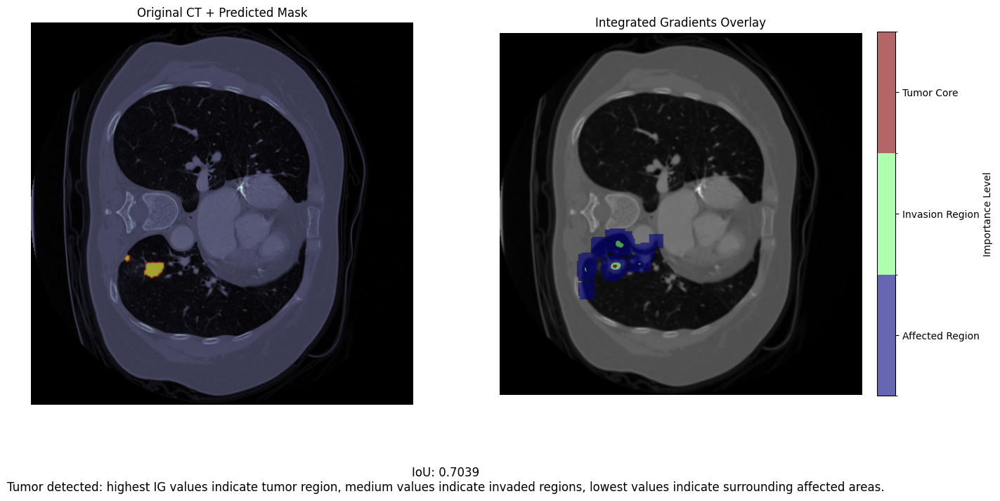

In [70]:
import torch
import numpy as np
import cv2
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.ndimage import gaussian_filter


class IntegratedGradients:
    def __init__(self, model, device='cuda'):
        """
        Integrated Gradients explainer for segmentation models.
        """
        self.model = model.to(device).eval()
        self.device = device

    def explain(self, image, steps=50, threshold=0.2):
        """
        Compute Integrated Gradients using a Gaussian-blurred baseline
        and apply threshold filtering.
        """
        input_tensor = torch.tensor(image).unsqueeze(0).unsqueeze(0).float().to(self.device)

        # Create Gaussian blur baseline
        baseline = gaussian_filter(image, sigma=5)
        baseline_tensor = torch.tensor(baseline).unsqueeze(0).unsqueeze(0).float().to(self.device)

        # Generate interpolated inputs
        scaled_inputs = torch.stack([
            baseline_tensor + (float(i) / steps) * (input_tensor - baseline_tensor)
            for i in range(steps + 1)
        ]).to(self.device)

        gradients = torch.zeros_like(input_tensor).to(self.device)

        for scaled_input in scaled_inputs:
            scaled_input.requires_grad = True
            output = torch.sigmoid(self.model(scaled_input)).mean()
            output.backward()
            gradients += scaled_input.grad.detach()
            scaled_input.requires_grad = False

        # Average gradients and integrate
        avg_gradients = gradients / steps
        integrated_gradients = (input_tensor - baseline_tensor) * avg_gradients
        integrated_gradients = integrated_gradients.cpu().numpy()[0, 0]

        # Normalize and threshold
        integrated_gradients = np.maximum(integrated_gradients, 0)
        if np.max(integrated_gradients) > 0:
            integrated_gradients /= np.max(integrated_gradients)

        integrated_gradients[integrated_gradients < threshold] = 0

        # Smooth result
        smoothed_ig_map = gaussian_filter(integrated_gradients, sigma=1)
        return smoothed_ig_map

    def visualize(self, image, ig_map, pred_binary, gt_slice=None, pred_label=1, alpha=0.6):
        """
        Visualize Integrated Gradients overlay on the original image.
        Also computes IoU if ground truth is provided.
        """

        # Normalize image
        img_norm = image - np.min(image)
        if np.max(img_norm) > 0:
            img_norm /= np.max(img_norm)

        # Slight blur for better IG visibility
        background = cv2.GaussianBlur(img_norm, (5, 5), sigmaX=1)

        # Compute IoU if ground truth exists
        iou = None
        if gt_slice is not None:
            gt_binary = (gt_slice > 0.5).astype(np.float32)
            intersection = (pred_binary * gt_binary).sum()
            union = ((pred_binary + gt_binary) > 0).sum()
            iou = intersection / union if union > 0 else 0.0

        # Explanation mapping
        def get_explanation(pred_label):
            explanations = {
                1: {
                    "text": "No tumor detected"
                },
                0: {
                    "text": "Tumor detected: highest IG values indicate tumor region, medium values indicate invaded regions, lowest values indicate surrounding affected areas."
                },
            }
            return explanations.get(pred_label, {})

        explanation = get_explanation(pred_label)

        # Mask IG values
        masked_ig = np.ma.masked_where(ig_map == 0, ig_map)

        # Predicted mask overlay
        pred_mask = np.ma.masked_where(pred_binary == 0, pred_binary)

        fig, axes = plt.subplots(1, 2, figsize=(16, 8))

        # Left: CT + Prediction
        axes[0].imshow(img_norm, cmap="bone")
        axes[0].imshow(pred_mask, alpha=0.5, cmap="autumn")
        axes[0].set_title("Original CT + Predicted Mask")
        axes[0].axis('off')

        # Right: CT + IG overlay
        axes[1].imshow(background, cmap='gray')

        bounds = [0, 0.2, 0.5, 1.0]
        labels = ['Affected Region', 'Invasion Region', 'Tumor Core']

        cmap = plt.cm.jet
        norm = mcolors.BoundaryNorm(bounds, cmap.N)

        im = axes[1].imshow(masked_ig, cmap=cmap, norm=norm, alpha=alpha)
        axes[1].set_title("Integrated Gradients Overlay")
        axes[1].axis('off')

        ticks = [0.1, 0.35, 0.75]
        cbar = fig.colorbar(im, ax=axes[1], ticks=ticks, fraction=0.046, pad=0.04)
        cbar.ax.set_yticklabels(labels)
        cbar.set_label("Importance Level")

        # Display info
        info_text = ""
        if iou is not None:
            info_text += f"IoU: {iou:.4f}\n"
        info_text += explanation.get("text", "")

        plt.subplots_adjust(bottom=0.2)
        plt.figtext(0.5, 0.05, info_text, wrap=True, ha='center', fontsize=12)

        plt.show()


# =========================================================
# USAGE
# =========================================================

ig_explainer = IntegratedGradients(model, device=device)

slice_idx = 84
ct_slice = ct[:, :, slice_idx]
slice_resized = cv2.resize(ct_slice, (256, 256))

# Compute IG
ig_map_resized = ig_explainer.explain(slice_resized, steps=200, threshold=0.2)

# Model prediction
with torch.no_grad():
    inp_t = torch.tensor(slice_resized).unsqueeze(0).unsqueeze(0).float().to(device)
    out = torch.sigmoid(model(inp_t)).cpu().numpy().squeeze()

pred_binary_resized = (out > 0.5).astype(np.float32)

# Resize back
ig_map = cv2.resize(ig_map_resized, (ct_slice.shape[1], ct_slice.shape[0]))
pred_binary = cv2.resize(pred_binary_resized, (ct_slice.shape[1], ct_slice.shape[0]))

# Ground truth (optional)
gt_slice = gt_array[:, :, slice_idx] if 'gt_array' in globals() else None

# Label decision
pred_label = 1 if pred_binary.mean() > 0.5 else 0

# Visualization
ig_explainer.visualize(ct_slice, ig_map, pred_binary, gt_slice, pred_label, alpha=0.6)

Running Occlusion Sensitivity on the entire CT volume...
Processing slice 1/211...
Slice 1 - IoU: 0.0000
Processing slice 2/211...
Slice 2 - IoU: 0.0000
Processing slice 3/211...
Slice 3 - IoU: 0.0000
Processing slice 4/211...
Slice 4 - IoU: 0.0000
Processing slice 5/211...
Slice 5 - IoU: 0.0000
Processing slice 6/211...
Slice 6 - IoU: 0.0000
Processing slice 7/211...
Slice 7 - IoU: 0.0000
Processing slice 8/211...
Slice 8 - IoU: 0.0000
Processing slice 9/211...
Slice 9 - IoU: 0.0000
Processing slice 10/211...
Slice 10 - IoU: 0.0000
Processing slice 11/211...
Slice 11 - IoU: 0.0000
Processing slice 12/211...
Slice 12 - IoU: 0.0000
Processing slice 13/211...
Slice 13 - IoU: 0.0000
Processing slice 14/211...
Slice 14 - IoU: 0.0000
Processing slice 15/211...
Slice 15 - IoU: 0.0000
Processing slice 16/211...
Slice 16 - IoU: 0.0000
Processing slice 17/211...
Slice 17 - IoU: 0.0000
Processing slice 18/211...
Slice 18 - IoU: 0.0000
Processing slice 19/211...
Slice 19 - IoU: 0.0000
Processing 

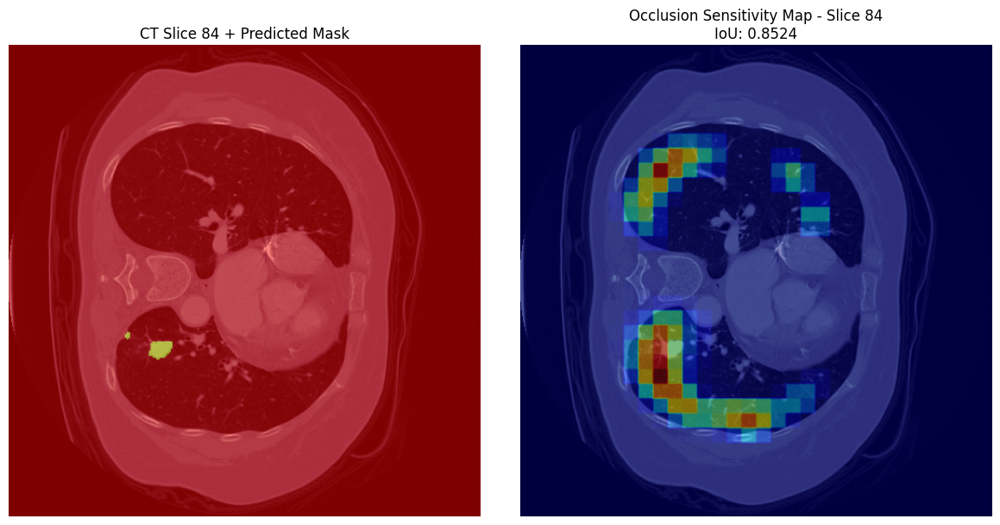

In [72]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cv2
import os

class ImprovedOcclusionSensitivity:
    def __init__(self, model, device='cuda'):
        self.model = model.to(device).eval()
        self.device = device

    def explain(self, image, patch_size=16, stride=8):
        """
        Tính Occlusion Sensitivity cho một lát cắt (image: H,W).
        Trả về: sensitivity_map và original_output (mask dự đoán ban đầu).
        """
        height, width = image.shape
        sensitivity_map = np.zeros((height, width), dtype=np.float32)
        image_tensor = torch.tensor(image).unsqueeze(0).unsqueeze(0).float().to(self.device)

        # Dự đoán ban đầu (original_output)
        with torch.no_grad():
            original_output = torch.sigmoid(self.model(image_tensor)).cpu().numpy().squeeze()

        # Duyệt qua từng patch
        for y in range(0, height, stride):
            for x in range(0, width, stride):
                occluded_image = image.copy()
                occluded_image[y:y+patch_size, x:x+patch_size] = 0

                occluded_tensor = torch.tensor(occluded_image).unsqueeze(0).unsqueeze(0).float().to(self.device)
                with torch.no_grad():
                    occluded_output = torch.sigmoid(self.model(occluded_tensor)).cpu().numpy().squeeze()

                # Đo sự thay đổi
                change = np.mean(np.abs(original_output - occluded_output))
                sensitivity_map[y:y+patch_size, x:x+patch_size] += change

        # Normalize map
        sensitivity_map = np.maximum(sensitivity_map, 0)
        if np.max(sensitivity_map) > 0:
            sensitivity_map /= np.max(sensitivity_map)
        return sensitivity_map, original_output

def calculate_iou(pred_binary, gt_binary):
    """
    Tính toán IoU giữa mask dự đoán và ground truth.
    """
    intersection = (pred_binary * gt_binary).sum()
    union = ((pred_binary + gt_binary) > 0).sum()
    return intersection / union if union > 0 else 0.0

def display_selected_slice(ct_slice, occlusion_map, pred_binary_slice, gt_slice, slice_idx, iou):
    """
    Hiển thị lát cắt được chọn cùng với Occlusion Sensitivity và IoU.
    """
    # Normalize CT slice
    img_norm = ct_slice - np.min(ct_slice)
    if np.max(img_norm) > 0:
        img_norm /= np.max(img_norm)
    img_norm = np.clip(img_norm * 1.5, 0, 1)

    # Hiển thị kết quả
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    # Trái: CT + Predicted Mask
    axes[0].imshow(img_norm, cmap="bone")
    axes[0].imshow(pred_binary_slice, alpha=0.5, cmap="autumn")
    axes[0].set_title(f"CT Slice {slice_idx} + Predicted Mask")
    axes[0].axis('off')

    # Phải: Occlusion Sensitivity Map
    axes[1].imshow(img_norm, cmap="bone")
    axes[1].imshow(occlusion_map, cmap="jet", alpha=0.5)
    axes[1].set_title(f"Occlusion Sensitivity Map - Slice {slice_idx}\nIoU: {iou:.4f}")
    axes[1].axis('off')

    plt.tight_layout()
    plt.show()

def run_occlusion_sensitivity_on_ct(model, ct, gt_array=None, patch_size=16, stride=8, output_dir="./results", device='cuda'):
    """
    Chạy Occlusion Sensitivity trên toàn bộ ảnh CT (chiều sâu D).
    """
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    occlusion_explainer = ImprovedOcclusionSensitivity(model, device=device)
    H, W, D = ct.shape
    total_intersection, total_union = 0, 0
    occlusion_maps = []
    pred_binary_maps = []

    print("Running Occlusion Sensitivity on the entire CT volume...")
    for slice_idx in range(D):
        print(f"Processing slice {slice_idx+1}/{D}...")
        ct_slice = ct[:, :, slice_idx]
        slice_resized = cv2.resize(ct_slice, (256, 256))

        # Tính Occlusion Sensitivity cho lát cắt này
        occlusion_map_resized, original_output_resized = occlusion_explainer.explain(slice_resized, patch_size, stride)

        # Tạo binary mask từ kết quả dự đoán
        pred_binary_resized = (original_output_resized > 0.5).astype(np.float32)

        # Resize về kích thước gốc
        occlusion_map_slice = cv2.resize(occlusion_map_resized, (ct_slice.shape[1], ct_slice.shape[0]), interpolation=cv2.INTER_LINEAR)
        pred_binary_slice = cv2.resize(pred_binary_resized, (ct_slice.shape[1], ct_slice.shape[0]), interpolation=cv2.INTER_NEAREST)

        # Tính IoU nếu có ground truth
        gt_slice = gt_array[:, :, slice_idx] if gt_array is not None else None
        if gt_slice is not None:
            gt_binary = (gt_slice > 0.5).astype(np.float32)
            intersection = (pred_binary_slice * gt_binary).sum()
            union = ((pred_binary_slice + gt_binary) > 0).sum()
            total_intersection += intersection
            total_union += union
            iou = intersection / union if union > 0 else 0.0
            print(f"Slice {slice_idx+1} - IoU: {iou:.4f}")
        else:
            print(f"Slice {slice_idx+1} - No Ground Truth")

        # Lưu kết quả vào list
        occlusion_maps.append(occlusion_map_slice)
        pred_binary_maps.append(pred_binary_slice)

    # Tính IoU tổng
    total_iou = total_intersection / total_union if total_union > 0 else 0.0
    print(f"Total IoU for the entire CT: {total_iou:.4f}")
    return occlusion_maps, pred_binary_maps, total_iou

# -------------------- Chạy trên CT và hiển thị lát cắt mong muốn --------------------

# Giả sử 'model', 'ct', 'gt_array', 'device' đã được định nghĩa ở trên
output_dir = "./occlusion_results"
occlusion_maps, pred_binary_maps, total_iou = run_occlusion_sensitivity_on_ct(model, ct, gt_array=gt_array, patch_size=16, stride=8, output_dir=output_dir, device=device)

# In IoU tổng
print(f"\nFinal Total IoU for the entire CT volume: {total_iou:.4f}")

# Hiển thị lát cắt được chọn
slice_idx_to_display = 84  # Thay đổi số này để chọn lát cắt mong muốn
ct_slice = ct[:, :, slice_idx_to_display]
occlusion_map_slice = occlusion_maps[slice_idx_to_display]
pred_binary_slice = pred_binary_maps[slice_idx_to_display]
gt_slice = gt_array[:, :, slice_idx_to_display] if 'gt_array' in globals() else None

iou = calculate_iou(pred_binary_slice, (gt_slice > 0.5).astype(np.float32)) if gt_slice is not None else None
display_selected_slice(ct_slice, occlusion_map_slice, pred_binary_slice, gt_slice, slice_idx_to_display, iou)


## Advanced Visualization Blocks

- Interactive 3D tumor mesh plotting
- Multi-slice 2D tumor overlay panel
- Tumor burden and intensity analysis graphs

In [73]:
import os
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from skimage import measure


# Resolve prediction volume from in-memory variables first, then fallback file paths.
def _resolve_prediction_volume():
    if "segmentation_array" in globals():
        arr = np.asarray(segmentation_array)
        return (arr > 0.5).astype(np.uint8)

    if "prediction" in globals():
        arr = np.asarray(prediction)
        return (arr > 0.5).astype(np.uint8)

    candidate_paths = [
        os.path.join(PRED_DIR, "predicted_segmentation.nii"),
        os.path.join(PRED_DIR, "predicted_segmentation.nii.gz"),
        "predicted_segmentation.nii",
        "predicted_segmentation.nii.gz",
    ]

    for path in candidate_paths:
        if os.path.exists(path):
            arr = nib.load(path).get_fdata()
            return (arr > 0.5).astype(np.uint8)

    raise FileNotFoundError(
        "Prediction volume not found. Run inference first so segmentation_array/prediction exists "
        "or save predicted_segmentation.nii."
    )


def create_3d_tumor_mesh(pred_mask, downsample=2, min_voxels=100):
    """Create interactive 3D tumor mesh using marching cubes."""
    pred_mask = (pred_mask > 0).astype(np.uint8)

    if downsample > 1:
        pred_mask = pred_mask[::downsample, ::downsample, ::downsample]

    tumor_voxels = int(pred_mask.sum())
    if tumor_voxels < min_voxels:
        print(f"Tumor voxels too few for mesh: {tumor_voxels}")
        return None

    verts, faces, _, _ = measure.marching_cubes(pred_mask, level=0.5, step_size=1)

    fig = go.Figure(
        data=[
            go.Mesh3d(
                x=verts[:, 0],
                y=verts[:, 1],
                z=verts[:, 2],
                i=faces[:, 0],
                j=faces[:, 1],
                k=faces[:, 2],
                color="red",
                opacity=0.65,
                name="Predicted Tumor",
            )
        ]
    )

    fig.update_layout(
        title="3D Tumor Mesh (Predicted Segmentation)",
        scene=dict(
            xaxis_title="X",
            yaxis_title="Y",
            zaxis_title="Z",
            aspectmode="data",
        ),
        width=900,
        height=700,
    )

    return fig


pred_mask_3d = _resolve_prediction_volume()
fig_mesh = create_3d_tumor_mesh(pred_mask_3d, downsample=2)

if fig_mesh is not None:
    os.makedirs(VIZ_DIR, exist_ok=True)
    mesh_html_path = os.path.join(VIZ_DIR, "predicted_tumor_3d_mesh.html")
    fig_mesh.write_html(mesh_html_path)
    fig_mesh.show()
    print(f"Saved 3D mesh visualization: {mesh_html_path}")

Saved 3D mesh visualization: E:\aryan\notebook_outputs\visualizations\predicted_tumor_3d_mesh.html


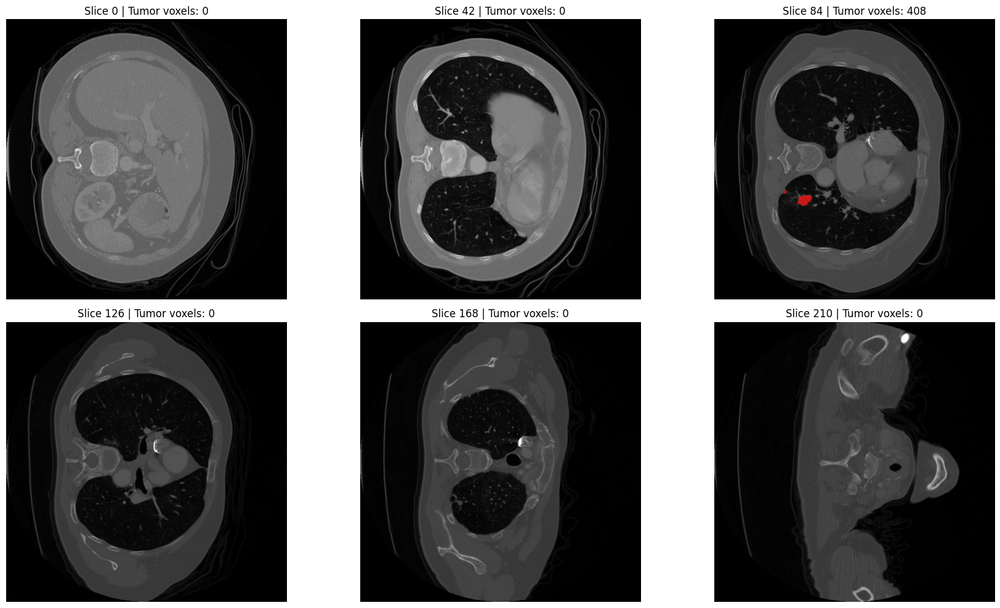

Saved multi-slice visualization: notebook_outputs/visualizations\predicted_tumor_multislice_overlay.png


In [74]:
import numpy as np
import matplotlib.pyplot as plt
import cv2


# Reuse prediction from previous cell if available.
if "pred_mask_3d" not in globals():
    pred_mask_3d = _resolve_prediction_volume()

# Resolve CT image volume if available in notebook context.
ct_volume = None
if "ct" in globals():
    ct_volume = np.asarray(ct)


def plot_multislice_overlay(ct_vol, pred_mask, num_slices=6):
    """2D multi-slice overlay similar to major.ipynb visualization style."""
    depth = pred_mask.shape[2]
    slice_ids = np.linspace(0, depth - 1, num_slices, dtype=int)

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()

    for idx, z in enumerate(slice_ids):
        ax = axes[idx]
        mask_slice = pred_mask[:, :, z]

        if ct_vol is not None and ct_vol.shape[:2] == pred_mask.shape[:2]:
            base = ct_vol[:, :, min(z, ct_vol.shape[2] - 1)]
            base = base - np.min(base)
            if np.max(base) > 0:
                base = base / np.max(base)
            ax.imshow(base, cmap="gray")
        else:
            ax.imshow(mask_slice, cmap="gray", alpha=0.15)

        mask_overlay = np.ma.masked_where(mask_slice == 0, mask_slice)
        ax.imshow(mask_overlay, cmap="autumn", alpha=0.7)
        ax.set_title(f"Slice {z} | Tumor voxels: {int(mask_slice.sum())}")
        ax.axis("off")

    plt.tight_layout()
    return fig


fig_multi = plot_multislice_overlay(ct_volume, pred_mask_3d, num_slices=6)
plt.show()

viz_dir = "notebook_outputs/visualizations"
os.makedirs(viz_dir, exist_ok=True)
multislice_path = os.path.join(viz_dir, "predicted_tumor_multislice_overlay.png")
fig_multi.savefig(multislice_path, dpi=250, bbox_inches="tight")
print(f"Saved multi-slice visualization: {multislice_path}")

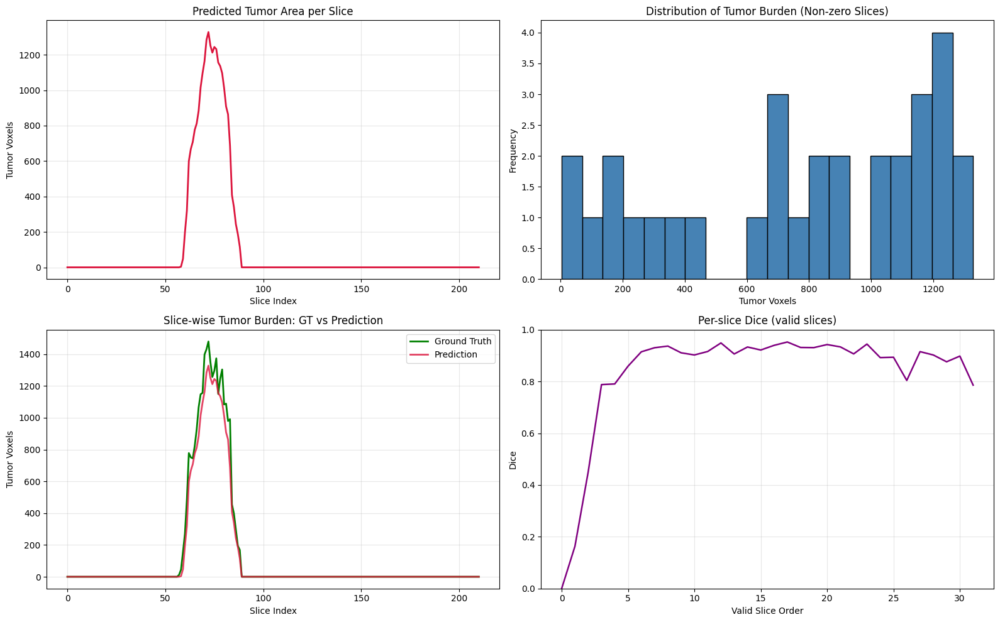

Saved analysis graphs: notebook_outputs/visualizations\tumor_burden_graphs.png


In [79]:
import numpy as np
import matplotlib.pyplot as plt


if "pred_mask_3d" not in globals():
    pred_mask_3d = _resolve_prediction_volume()

# Optional ground-truth support if available earlier in notebook.
gt_vol = None
if "gt_array" in globals():
    gt_vol = (np.asarray(gt_array) > 0.5).astype(np.uint8)

# Tumor burden statistics across slices.
pred_area_per_slice = pred_mask_3d.sum(axis=(0, 1))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(pred_area_per_slice, color="crimson", lw=2)
axes[0, 0].set_title("Predicted Tumor Area per Slice")
axes[0, 0].set_xlabel("Slice Index")
axes[0, 0].set_ylabel("Tumor Voxels")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].hist(pred_area_per_slice[pred_area_per_slice > 0], bins=20, color="steelblue", edgecolor="black")
axes[0, 1].set_title("Distribution of Tumor Burden (Non-zero Slices)")
axes[0, 1].set_xlabel("Tumor Voxels")
axes[0, 1].set_ylabel("Frequency")

if gt_vol is not None and gt_vol.shape == pred_mask_3d.shape:
    gt_area_per_slice = gt_vol.sum(axis=(0, 1))
    axes[1, 0].plot(gt_area_per_slice, label="Ground Truth", color="green", lw=2)
    axes[1, 0].plot(pred_area_per_slice, label="Prediction", color="crimson", lw=2, alpha=0.8)
    axes[1, 0].set_title("Slice-wise Tumor Burden: GT vs Prediction")
    axes[1, 0].set_xlabel("Slice Index")
    axes[1, 0].set_ylabel("Tumor Voxels")
    axes[1, 0].legend()
    axes[1, 0].grid(True, alpha=0.3)

    dice_per_slice = []
    for i in range(pred_mask_3d.shape[2]):
        p = pred_mask_3d[:, :, i]
        g = gt_vol[:, :, i]
        denom = p.sum() + g.sum()
        d = (2 * (p * g).sum() / denom) if denom > 0 else np.nan
        dice_per_slice.append(d)

    dice_per_slice = np.array(dice_per_slice, dtype=float)
    valid_dice = dice_per_slice[~np.isnan(dice_per_slice)]
    axes[1, 1].plot(valid_dice, color="purple", lw=1.8)
    axes[1, 1].set_title("Per-slice Dice (valid slices)")
    axes[1, 1].set_xlabel("Valid Slice Order")
    axes[1, 1].set_ylabel("Dice")
    axes[1, 1].set_ylim(0, 1)
    axes[1, 1].grid(True, alpha=0.3)
else:
    nonzero = pred_area_per_slice[pred_area_per_slice > 0]
    if len(nonzero) > 0:
        cumulative = np.cumsum(nonzero) / np.sum(nonzero)
        axes[1, 0].plot(cumulative, color="darkorange", lw=2)
        axes[1, 0].set_title("Cumulative Tumor Burden (Non-zero Slices)")
        axes[1, 0].set_xlabel("Sorted Non-zero Slice Order")
        axes[1, 0].set_ylabel("Cumulative Fraction")
        axes[1, 0].set_ylim(0, 1)
        axes[1, 0].grid(True, alpha=0.3)

    axes[1, 1].boxplot([pred_area_per_slice[pred_area_per_slice > 0]], labels=["Predicted"])
    axes[1, 1].set_title("Tumor Burden Boxplot")
    axes[1, 1].set_ylabel("Tumor Voxels")

plt.tight_layout()
plt.show()

viz_dir = "notebook_outputs/visualizations"
os.makedirs(viz_dir, exist_ok=True)
graphs_path = os.path.join(viz_dir, "tumor_burden_graphs.png")
fig.savefig(graphs_path, dpi=250, bbox_inches="tight")
print(f"Saved analysis graphs: {graphs_path}")

In [81]:
# --- Priority Segmentation Metrics: IoU, Dice, Volume Similarity, Precision, F1 ---

import numpy as np
from sklearn.metrics import precision_score, f1_score

def compute_priority_metrics(preds, labels, threshold=0.5):
    """
    preds: numpy array, predicted mask (float or bool)
    labels: numpy array, ground truth mask (float or bool)
    """
    preds_bin = (preds > threshold).astype(np.uint8).flatten()
    labels_bin = (labels > 0.5).astype(np.uint8).flatten()

    intersection = np.logical_and(preds_bin, labels_bin).sum()
    union = np.logical_or(preds_bin, labels_bin).sum()
    dice = (2. * intersection) / (preds_bin.sum() + labels_bin.sum() + 1e-8)
    iou = intersection / (union + 1e-8)
    precision = precision_score(labels_bin, preds_bin, zero_division=0)
    f1 = f1_score(labels_bin, preds_bin, zero_division=0)
    # Volume similarity: 1 - |A - B| / (A + B)
    vol_pred = preds_bin.sum()
    vol_gt = labels_bin.sum()
    volume_similarity = 1 - abs(vol_pred - vol_gt) / (vol_pred + vol_gt + 1e-8)

    return {
        'IoU': iou,
        'Dice': dice,
        'Precision': precision,
        'F1': f1
    }

# Example usage:
# all_preds = ... # your predicted mask, shape (N, H, W) or (H, W)
# all_labels = ... # your ground truth mask, same shape
# metrics = compute_priority_metrics(all_preds, all_labels)
# for k, v in metrics.items():
#     print(f"{k}: {v:.4f}")

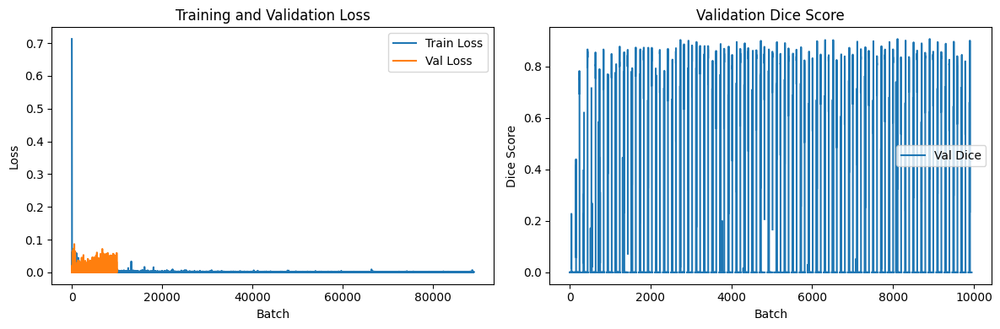

In [85]:
import matplotlib.pyplot as plt

# After training is complete
train_losses = model.train_losses
val_losses = model.val_losses
val_dices = model.val_dices

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Val Loss')
plt.xlabel('Batch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(val_dices, label='Val Dice')
plt.xlabel('Batch')
plt.ylabel('Dice Score')
plt.title('Validation Dice Score')
plt.legend()

plt.tight_layout()
plt.show()

all_preds = []
all_labels = []

model.eval()
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)
        outputs = torch.sigmoid(model(images))
        preds = (outputs > 0.5).cpu().numpy().astype(int).flatten()
        labels_np = labels.cpu().numpy().astype(int).flatten()
        all_preds.extend(preds)
        all_labels.extend(labels_np)

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

In [86]:
metrics = compute_priority_metrics(all_preds, all_labels)
for k, v in metrics.items():
    print(f"{k}: {v:.4f}")

IoU: 0.4569
Dice: 0.6272
Precision: 0.9028
F1: 0.6272
